# **2. Motivos de Cartão e Detecção de VAR: Embeddings, BERTopic e Rotulagem Semântica**

Este notebook implementa um pipeline NLP para analisar as justificativas livres de cartões amarelos e vermelhos e os motivos de acréscimos nas súmulas do Campeonato Brasileiro.

**Cartões:** identificar o *tipo de falta* por trás de cada cartão, caracterizando o perfil de marcação de cada árbitro e o padrão de infrações de cada time.

**Acréscimos/atrasos:** detectar, de forma binária, se há menção ao VAR na justificativa registrada pelo árbitro.

## Pipeline de Motivos de Cartão

1. **Embeddings base** — `multilingual-e5-large` (1024 dim) aplicado ao conjunto de textos únicos de justificativas, com prefixos `passage:` / `query:` conforme protocolo E5.
2. **Seleção de hiperparâmetros** — grid search sobre `n_neighbors` (UMAP) e `min_topic_size` (HDBSCAN) via Silhouette Score.
3. **BERTopic — Passagem 1** — clustering exploratório com o modelo base; gera pares positivos para o fine-tuning.
4. **Fine-tuning** — `MultipleNegativesRankingLoss` com pares derivados dos clusters da Passagem 1 (*self-supervised contrastive learning*, Gao et al. 2021).
5. **BERTopic — Passagem 2** — clusters finais com embeddings do modelo fine-tunado.
6. **Ablação** — comparação Pass 1 vs. Pass 2 em número de clusters, taxa de outliers e Silhouette Score.
7. **Rotulagem semântica via LLM** — `claude-haiku-4-5` classifica cada cluster (top-15 textos representativos) em grupos-semente ou propõe novos grupos; outliers HDBSCAN são classificados em batches.


## **1. Bibliotecas**

- `sentence-transformers` — embeddings semânticos e fine-tuning com `MultipleNegativesRankingLoss`
- `bertopic` — clustering temático via UMAP + HDBSCAN + c-TF-IDF
- `umap-learn` — redução de dimensionalidade antes do HDBSCAN
- `scikit-learn` — Silhouette Score como métrica de qualidade de clustering

In [1]:
import json
import re
import shutil
import unicodedata
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sentence_transformers import models as st_models
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 220)
plt.style.use("seaborn-v0_8-whitegrid")

/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/x8/hw9x5p0d1v9bjf56_4xc8qrh0000gn/T/ipykernel_75307/1646475206.py:14: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import models as st_models


## **2. Configuração**

Caminhos, hiperparâmetros e flags de execução. O modelo fine-tunado é reutilizado quando já existe em `models/`, evitando re-treinar em execuções subsequentes.

| Parâmetro | Valor | Descrição |
|-----------|-------|-----------|
| `MODEL_NAME` | `intfloat/multilingual-e5-large` | Modelo de embeddings — multilingual, 1024 dim |
| `MODEL_NAME_BASELINE` | `paraphrase-multilingual-mpnet-base-v2` | Modelo anterior (768 dim), mantido como referência de ablação |
| `ENCODE_PREFIX_PASSAGE` | `"passage: "` | Prefixo obrigatório para passagens no protocolo E5 |
| `ENCODE_PREFIX_QUERY` | `"query: "` | Prefixo obrigatório para consultas no protocolo E5 |
| `FINETUNE_EPOCHS` | 1 | Uma epoch evita overfitting com pares sintéticos em corpus pequeno |
| `BERTOPIC_NGRAM_RANGE` | (1, 3) | Captura expressões como "falta tática" e "ataque promissor" |
| `LLM_MODEL` | `claude-haiku-4-5-20251001` | Modelo LLM para rotulagem semântica dos clusters |
| `LLM_N_EXAMPLES` | 15 | Textos representativos enviados ao LLM por cluster |


In [2]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
VIZ_PATH = PROJECT_ROOT / "viz"
OUTPUT_DIR = PROCESSED_PATH / "semantic_reasons"
CARD_OUTPUT_DIR = OUTPUT_DIR / "card_reasons"
DELAY_OUTPUT_DIR = OUTPUT_DIR / "delay_reasons"

CARD_REASONS_PATH = PROCESSED_PATH / "card_reasons.csv"
DELAY_REASONS_PATH = PROCESSED_PATH / "delay_reasons.csv"

for directory in [MODELS_DIR, OUTPUT_DIR, CARD_OUTPUT_DIR, DELAY_OUTPUT_DIR, VIZ_PATH]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

MODEL_NAME_BASELINE = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
MODEL_NAME          = "intfloat/multilingual-e5-large"
FINETUNED_MODEL_DIR = MODELS_DIR / "football_card_reason_e5_large_two_pass"
ENCODE_PREFIX_PASSAGE = "passage: "
ENCODE_PREFIX_QUERY   = "query: "

RUN_FINE_TUNING = True
RETRAIN_FINETUNED_MODEL = False
USE_FINETUNED_IF_AVAILABLE = True
FINETUNE_EPOCHS = 1
FINETUNE_BATCH_SIZE = 32
MAX_TEXTS_PER_GROUP_FOR_FINETUNE = 220
MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE = 450

CARD_MIN_TOPIC_SIZE = 45
DELAY_MIN_TOPIC_SIZE = 35
BERTOPIC_NGRAM_RANGE = (1, 3)

CARD_TEXT_COLUMN = "card_reason_text"
CARD_TEXT_KEY_COLUMN = "card_reason_text_key"
DELAY_TEXT_COLUMN = "delay_reason_clean"

TOP_N_CARD_TEXTS = 15
TOP_N_TEAMS = 15
TOP_N_REFEREES = 15

def save_plot(fig, filename: str) -> None:
    fig.savefig(VIZ_PATH / filename, dpi=300, bbox_inches="tight")


## **3. Carregamento e Pré-processamento dos Dados**

Os dois arquivos de entrada são gerados no notebook 1. Para cartões, o texto de justificativa (`card_reason_text`) passa por normalização Unicode e remoção de pontuação — necessário para reduzir a fragmentação no vocabulário do BERTopic e para que variações ortográficas como "calçar" e "calcar" gerem embeddings próximos. Para atrasos, o campo `delay_reason` é mantido em forma original para análise léxica posterior.

In [3]:
REQUIRED_CARD_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro",
    "card_type", "team", "minute", "half", "reason", "reason_key",
}
REQUIRED_DELAY_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro", "delay_reason",
}

cards = pd.read_csv(CARD_REASONS_PATH, keep_default_na=False)
delays = pd.read_csv(DELAY_REASONS_PATH, keep_default_na=False)

missing_cards = REQUIRED_CARD_COLUMNS.difference(cards.columns)
missing_delays = REQUIRED_DELAY_COLUMNS.difference(delays.columns)
if missing_cards:
    raise ValueError(f"Colunas ausentes em {CARD_REASONS_PATH.name}: {sorted(missing_cards)}")
if missing_delays:
    raise ValueError(f"Colunas ausentes em {DELAY_REASONS_PATH.name}: {sorted(missing_delays)}")

cards.head(3)

,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key
0,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Figueirense,7,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.
1,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Guarani,15,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.


In [4]:
def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.casefold()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

cards[CARD_TEXT_COLUMN] = cards["reason"].fillna("").astype(str).str.strip()
cards[CARD_TEXT_KEY_COLUMN] = cards[CARD_TEXT_COLUMN].map(normalize_text)
cards = cards[cards[CARD_TEXT_KEY_COLUMN].ne("")].reset_index(drop=True)

delays[DELAY_TEXT_COLUMN] = delays["delay_reason"].fillna("").astype(str).str.strip()
delays[DELAY_TEXT_COLUMN] = delays[DELAY_TEXT_COLUMN].where(delays[DELAY_TEXT_COLUMN].ne(""), "n/a")
delays["delay_reason_key"] = delays[DELAY_TEXT_COLUMN].map(normalize_text)

pd.Series({
    "card_rows": len(cards),
    "unique_card_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
    "delay_rows": len(delays),
    "unique_delay_reason_texts": delays["delay_reason_key"].nunique(),
    "delay_na": delays[DELAY_TEXT_COLUMN].eq("n/a").sum(),
})

card_rows                    25752
unique_card_reason_texts      6940
delay_rows                    5663
unique_delay_reason_texts     3765
delay_na                        52
dtype: int64

## **4. Análise Exploratória dos Cartões**

Volume por ano, tipo e distribuição das justificativas mais frequentes. A concentração de textos recorrentes orienta o `min_topic_size` do BERTopic: textos com centenas de ocorrências formam clusters densos; textos raros tendem a ser outliers HDBSCAN.

In [5]:
card_dataset_summary = pd.Series({
    "cards": len(cards),
    "yellow_cards": int(cards["card_type"].eq("yellow").sum()),
    "red_cards": int(cards["card_type"].eq("red").sum()),
    "teams": cards["team"].nunique(),
    "referees": cards["arbitro"].nunique(),
    "unique_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
})
card_dataset_summary

cards                  25752
yellow_cards           24573
red_cards               1179
teams                    248
referees                 173
unique_reason_texts     6940
dtype: int64

In [6]:
card_by_year_type = pd.crosstab(cards["year"], cards["card_type"])
card_by_year_type

card_type,red,yellow
year,,
2020,197,3692
2021,170,3603
2022,180,3842
2023,174,3868
2024,187,4066
2025,184,3895
2026,87,1607


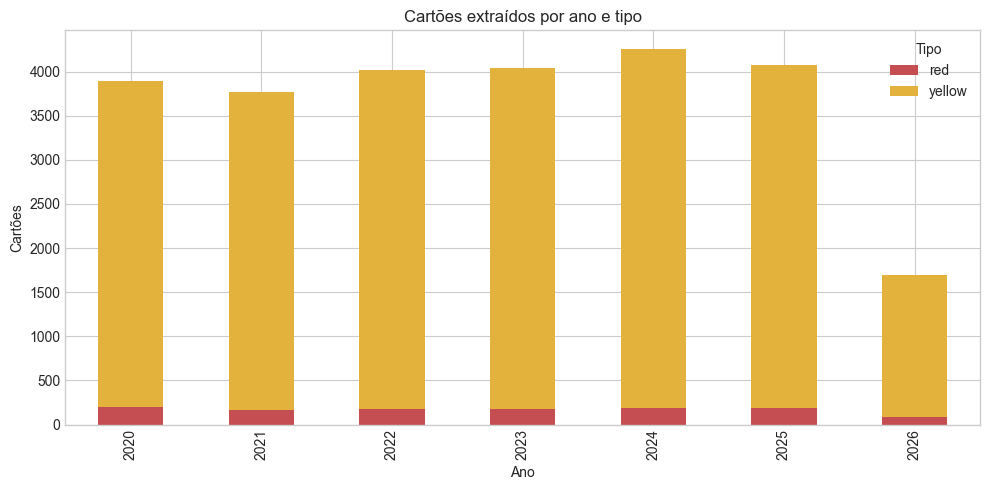

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = {"yellow": "#E3B23C", "red": "#C44E52"}
card_by_year_type.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[colors.get(column, "#4C78A8") for column in card_by_year_type.columns],
)
ax.set_title("Cartões extraídos por ano e tipo")
ax.set_xlabel("Ano")
ax.set_ylabel("Cartões")
ax.legend(title="Tipo")
plt.tight_layout()
save_plot(fig, "cards_by_year_type.png")
plt.show()

In [8]:
card_text_counts = (
    cards.groupby(CARD_TEXT_KEY_COLUMN)
    .agg(
        text_for_embedding=(CARD_TEXT_COLUMN, "first"),
        n_events=(CARD_TEXT_COLUMN, "size"),
        n_yellow=("card_type", lambda values: (values == "yellow").sum()),
        n_red=("card_type", lambda values: (values == "red").sum()),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
    .reset_index(drop=True)
)

card_texts = card_text_counts["text_for_embedding"].tolist()
card_text_counts.head(25)

,card_reason_text_key,text_for_embedding,n_events,n_yellow,n_red
0,por calcar seu adversario de maneira temeraria na disputa de bola,Por calçar seu adversário de maneira temerária na disputa de bola.,500,500,0
1,por cometer uma falta tatica impedindo um ataque promissor,"Por cometer uma falta tática, impedindo um ataque promissor.",410,410,0
2,por retardar o reinicio de jogo,Por retardar o reinicio de jogo,333,333,0
3,cometer uma falta tatica para impedir um ataque promissor,Cometer uma falta tática para impedir um ataque promissor.,285,284,1
4,por cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática para impedir um ataque promissor.,248,247,1
5,por calcar seu adversario de maneira temeraria na disputa da bola,"Por calçar seu adversário de maneira temerária, na disputa da bola",236,236,0
6,por calcar seu adversario de forma temeraria na disputa de bola,Por calçar seu adversário de forma temerária na disputa de bola.,228,228,0
7,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,224,223,1
8,por reclamar contra as decisoes da arbitragem,Por reclamar contra as decisões da arbitragem.,202,202,0
9,por impedir um ataque promissor,Por impedir um ataque promissor.,202,202,0


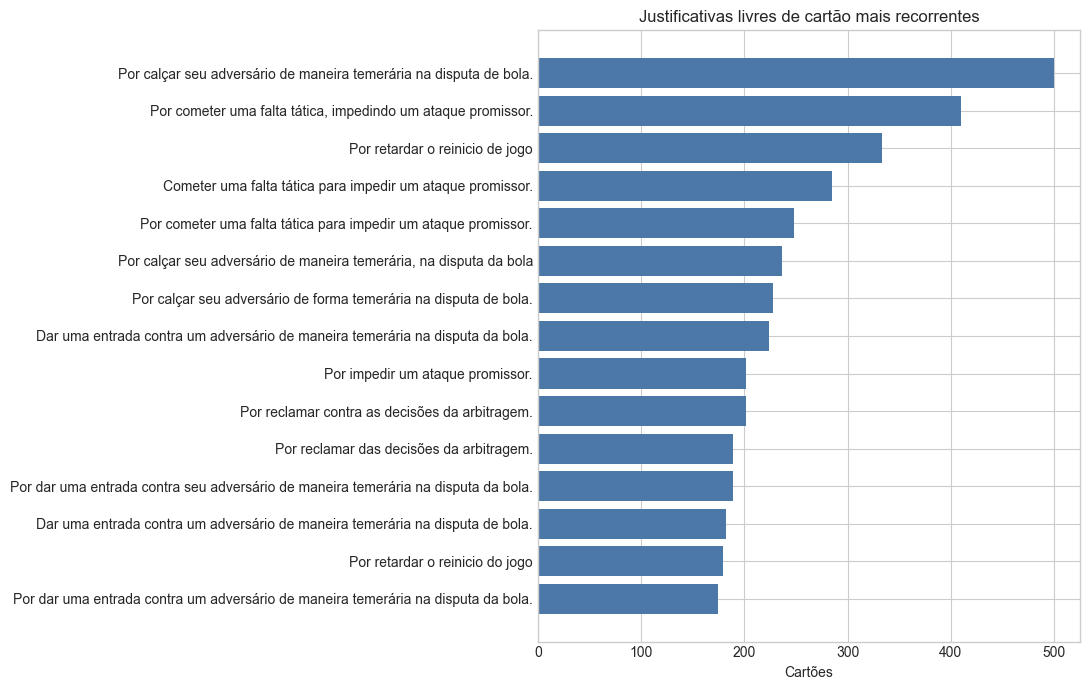

In [9]:
plot_top_texts = card_text_counts.head(TOP_N_CARD_TEXTS).sort_values("n_events")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(plot_top_texts["text_for_embedding"], plot_top_texts["n_events"], color="#4C78A8")
ax.set_title("Justificativas livres de cartão mais recorrentes")
ax.set_xlabel("Cartões")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "top_card_reason_texts.png")
plt.show()

## **5. Funções Auxiliares**

- `make_topic_model` — cria BERTopic com `embedding_model=None` para usar embeddings pré-calculados; UMAP com `n_components=5`, `metric="cosine"` e `min_dist=0.0` conforme recomendação do BERTopic.
- `load_embedding_model` — carrega `SentenceTransformer` com fallback para transformer puro + mean pooling.
- `silhouette_no_outliers` — exclui label -1 antes do Silhouette Score; incluir outliers como pseudo-classe inflaria artificialmente a métrica.
- `build_topic_summary` — agrega contagens de eventos e termos top por cluster.
- `top_examples_by_topic` — exemplos representativos por tópico, ordenados por frequência.
- `print_cluster_inspection` — formata clusters para inspeção antes da rotulagem semântica.


In [10]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "apos", "ate", "contra", "durante", "forma", "maneira", "motivo", "pela", "pelo", "pelas", "pelos",
    "num", "numa", "ter", "tendo", "dado", "haver", "havendo", "advertido", "advertida", "advertir",
    "adversario", "adversaria", "atleta", "jogador", "jogadora", "sr", "sra", "numero", "n", "equipe",
    "bola", "campo", "disputa", "jogada", "jogo", "partida", "seu", "sua", "seus", "suas", "foi", "foram",
    "acrescimo", "acrescimos", "devido", "inicio", "reinicio", "tempo", "minuto", "minutos", "jogadores",
}

def make_topic_model(min_topic_size: int, n_neighbors: int = 15) -> BERTopic:
    vectorizer_model = CountVectorizer(
        stop_words=list(PORTUGUESE_STOPWORDS),
        ngram_range=BERTOPIC_NGRAM_RANGE,
        min_df=2,
    )
    umap_model = umap.UMAP(n_components=5, n_neighbors=n_neighbors, min_dist=0.0, metric="cosine", random_state=RANDOM_STATE)
    return BERTopic(
        language="multilingual",
        embedding_model=None,
        umap_model=umap_model,
        vectorizer_model=vectorizer_model,
        min_topic_size=min_topic_size,
        calculate_probabilities=False,
        verbose=False,
    )

def silhouette_no_outliers(embeddings: np.ndarray, labels, sample_size: int = 3000) -> float:
    mask = np.array(labels) != -1
    if mask.sum() < 2:
        return float('nan')
    return float(
        silhouette_score(
            embeddings[mask], np.array(labels)[mask],
            sample_size=min(sample_size, int(mask.sum())),
            random_state=RANDOM_STATE,
        )
    )

def topic_words(topic_model: BERTopic, topic_id: int, top_n: int = 8) -> str:
    if topic_id == -1:
        return "outliers"
    words = topic_model.get_topic(topic_id) or []
    return ", ".join(word for word, _ in words[:top_n])

def build_topic_summary(topic_model: BERTopic, text_counts: pd.DataFrame, topic_col: str) -> pd.DataFrame:
    topic_info = topic_model.get_topic_info().rename(columns={"Topic": topic_col})
    event_counts = (
        text_counts.groupby(topic_col)
        .agg(
            n_unique_texts=("text_for_embedding", "size"),
            n_events=("n_events", "sum"),
        )
        .reset_index()
    )
    summary = topic_info.merge(event_counts, on=topic_col, how="left")
    summary["top_terms"] = summary[topic_col].map(lambda topic_id: topic_words(topic_model, int(topic_id)))
    return summary.sort_values("n_events", ascending=False).reset_index(drop=True)

def top_examples_by_topic(text_counts: pd.DataFrame, topic_col: str, top_n: int = 5) -> pd.DataFrame:
    columns = [topic_col, "n_events", "text_for_embedding"]
    return (
        text_counts.sort_values([topic_col, "n_events"], ascending=[True, False])
        .groupby(topic_col)
        .head(top_n)
        [columns]
        .reset_index(drop=True)
    )


def load_embedding_model(model_name_or_path) -> SentenceTransformer:
    path = str(model_name_or_path)
    try:
        model = SentenceTransformer(path)
        print(f"[OK] SentenceTransformer: {path}")
        return model
    except Exception:
        word_model = st_models.Transformer(path, max_seq_length=256)
        pooling = st_models.Pooling(
            word_model.get_word_embedding_dimension(),
            pooling_mode_mean_tokens=True,
        )
        model = SentenceTransformer(modules=[word_model, pooling])
        print(f"[OK] Transformer + mean pooling: {path}")
        return model

def model_dir_ready(path: Path) -> bool:
    return (path / "modules.json").exists()

def print_cluster_inspection(
    topic_model: BERTopic,
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n_examples: int = 3,
) -> None:
    summary = build_topic_summary(topic_model, text_counts, topic_col)
    examples_df = top_examples_by_topic(text_counts, topic_col, top_n=top_n_examples)

    print(f"{'ID':>4}  {'Eventos':>8}  Top terms")
    print("-" * 110)
    for _, row in summary.iterrows():
        topic_id = int(row[topic_col])
        n_events = int(row.get("n_events", 0))
        terms = str(row["top_terms"])
        suffix = "  [outliers HDBSCAN]" if topic_id == -1 else ""
        print(f"\n{topic_id:>4}  {n_events:>8,}  {terms}{suffix}")
        examples = examples_df[examples_df[topic_col].eq(topic_id)]["text_for_embedding"].tolist()
        for example in examples:
            print(f"              > {str(example)[:108]}")

## **6. Pipeline NLP — Motivos de Cartão**

Arquitetura de duas passagens: o modelo base produz clusters exploratórios que geram os pares de treino para o fine-tuning; o modelo fine-tunado produz os clusters finais usados na rotulagem semântica.

### **6.1 Embeddings Base**

`multilingual-e5-large` (1024 dim) aplicado ao conjunto de textos únicos de justificativas. O modelo exige prefixos `passage:` nos textos a indexar e `query:` nas consultas — protocolo obrigatório da família E5 para maximizar a qualidade dos embeddings.

Trabalhar sobre textos únicos — e não sobre todas as ocorrências — reduz o custo computacional do UMAP+HDBSCAN e elimina o viés de duplicatas nos embeddings de cluster.


In [11]:
base_model = load_embedding_model(MODEL_NAME)

base_card_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
base_card_embeddings = np.asarray(base_card_embeddings)
print(f"Embeddings base: {base_card_embeddings.shape}")

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 8007.72it/s]


[OK] SentenceTransformer: intfloat/multilingual-e5-large


Batches: 100%|██████████| 109/109 [00:39<00:00,  2.76it/s]

Embeddings base: (6940, 1024)


### **6.2 Seleção de Hiperparâmetros UMAP e HDBSCAN**

Os dois parâmetros com maior impacto na qualidade dos clusters são `n_neighbors` (UMAP) e `min_topic_size` (HDBSCAN), conforme documentado por Grootendorst (2022):

- **`n_neighbors`** — equilíbrio entre estrutura local e global na projeção UMAP. Valores menores criam fronteiras mais nítidas; valores maiores capturam estrutura global.
- **`min_topic_size`** — threshold de densidade do HDBSCAN; determina o número de clusters e a taxa de outliers.

`min_dist=0.0` é fixado conforme recomendação explícita do BERTopic para maximizar a densidade dos clusters. O Silhouette Score (excluindo outliers HDBSCAN) é a métrica de seleção — maior score indica clusters mais coesos no espaço original de 768 dimensões. Os resultados do grid search são salvos em CSV e reutilizados em execuções subsequentes.

Grid search base carregado do cache (grid_search_results_base_intfloat_multilingual-e5-large.csv)

Melhores parâmetros (base): n_neighbors=30, min_topic_size=15
Silhouette: 0.1222 | clusters: 113 | outliers: 1312


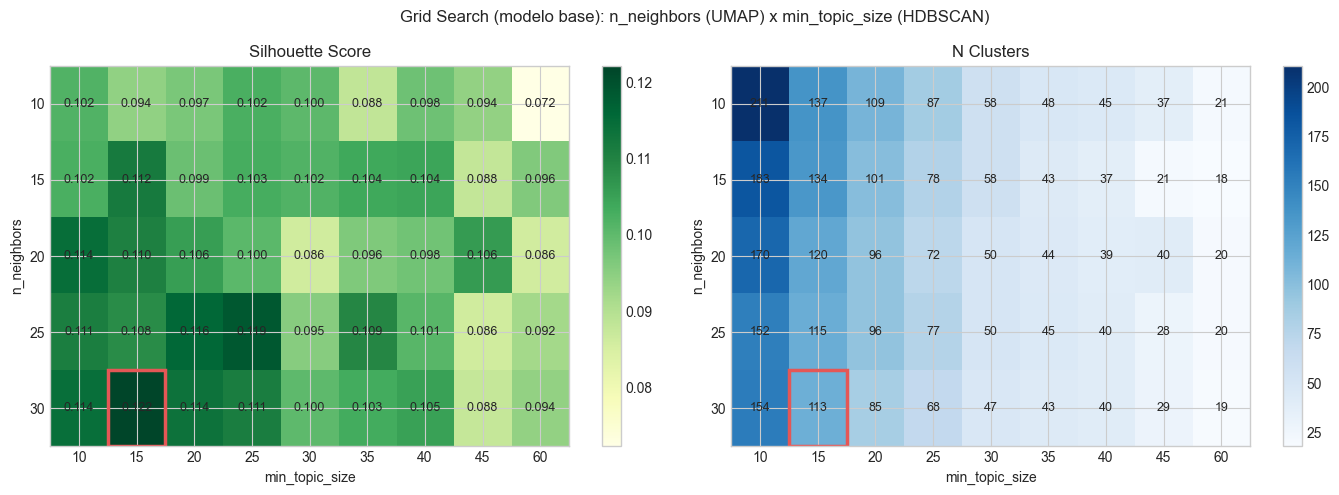

,n_neighbors,min_topic_size,n_clusters,n_outliers,outlier_pct,silhouette
0,10,10,211,1117,0.161,0.101547
1,10,15,137,1206,0.174,0.094154
2,10,20,109,1201,0.173,0.096995
3,10,25,87,1153,0.166,0.102480
4,10,30,58,733,0.106,0.100189
5,10,35,48,758,0.109,0.088195
6,10,40,45,1073,0.155,0.098248
7,10,45,37,695,0.100,0.093931
8,10,60,21,232,0.033,0.072225
9,15,10,183,1148,0.165,0.102346


In [12]:
MODEL_SLUG = MODEL_NAME.replace("/", "_")
GRID_SEARCH_BASE_PATH = OUTPUT_DIR / f"grid_search_results_base_{MODEL_SLUG}.csv"
RERUN_GRID_SEARCH = False

N_NEIGHBORS_RANGE = [10, 15, 20, 25, 30]
MIN_TOPIC_SIZE_RANGE = [10, 15, 20, 25, 30, 35, 40, 45, 60]

def _ranges_match(df: pd.DataFrame) -> bool:
    return (
        sorted(df["n_neighbors"].unique().tolist()) == sorted(N_NEIGHBORS_RANGE)
        and sorted(df["min_topic_size"].unique().tolist()) == sorted(MIN_TOPIC_SIZE_RANGE)
    )

def _run_grid_search(embeddings: np.ndarray, label: str) -> pd.DataFrame:
    combos = [(n, m) for n in N_NEIGHBORS_RANGE for m in MIN_TOPIC_SIZE_RANGE]
    results = []
    for i, (n_nb, mts) in enumerate(combos):
        _m = make_topic_model(mts, n_neighbors=n_nb)
        _topics, _ = _m.fit_transform(card_texts, embeddings=embeddings)
        _n_clusters = len(set(_topics) - {-1})
        _n_outliers = int((np.array(_topics) == -1).sum())
        _sil = silhouette_no_outliers(embeddings, _topics)
        results.append({"n_neighbors": n_nb, "min_topic_size": mts,
                         "n_clusters": _n_clusters, "n_outliers": _n_outliers,
                         "outlier_pct": round(_n_outliers / len(_topics), 3), "silhouette": _sil})
        print(f"  [{i+1:2d}/{len(combos)}] n_neighbors={n_nb:2d} | min_topic_size={mts:2d} | clusters={_n_clusters:3d} | outliers={_n_outliers:4d} | silhouette={float(_sil):.4f}")
    return pd.DataFrame(results)

if not RERUN_GRID_SEARCH and GRID_SEARCH_BASE_PATH.exists():
    grid_df = pd.read_csv(GRID_SEARCH_BASE_PATH)
    if not _ranges_match(grid_df):
        print("Ranges alterados — re-executando grid search base...")
        RERUN_GRID_SEARCH = True
    else:
        print(f"Grid search base carregado do cache ({GRID_SEARCH_BASE_PATH.name})")

if RERUN_GRID_SEARCH or not GRID_SEARCH_BASE_PATH.exists():
    print("Grid search: n_neighbors x min_topic_size (modelo base)...")
    grid_df = _run_grid_search(base_card_embeddings, "base")
    grid_df.to_csv(GRID_SEARCH_BASE_PATH, index=False)
    print(f"Salvo em {GRID_SEARCH_BASE_PATH}")

valid_grid = grid_df.dropna(subset=["silhouette"])
best_row = valid_grid.loc[valid_grid["silhouette"].idxmax()]
best_n_neighbors = int(best_row["n_neighbors"])
best_min_topic_size = int(best_row["min_topic_size"])
print(f"\nMelhores parâmetros (base): n_neighbors={best_n_neighbors}, min_topic_size={best_min_topic_size}")
print(f"Silhouette: {best_row['silhouette']:.4f} | clusters: {int(best_row['n_clusters'])} | outliers: {int(best_row['n_outliers'])}")

sil_pivot = grid_df.pivot(index="n_neighbors", columns="min_topic_size", values="silhouette")
nc_pivot  = grid_df.pivot(index="n_neighbors", columns="min_topic_size", values="n_clusters")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pivot, title, cmap in zip(
    axes, [sil_pivot, nc_pivot], ["Silhouette Score", "N Clusters"], ["YlGn", "Blues"],
):
    im = ax.imshow(pivot.values, aspect="auto", cmap=cmap)
    ax.set_xticks(range(len(MIN_TOPIC_SIZE_RANGE)))
    ax.set_xticklabels(MIN_TOPIC_SIZE_RANGE)
    ax.set_yticks(range(len(N_NEIGHBORS_RANGE)))
    ax.set_yticklabels(N_NEIGHBORS_RANGE)
    ax.set_xlabel("min_topic_size")
    ax.set_ylabel("n_neighbors")
    ax.set_title(title)
    for ii in range(len(N_NEIGHBORS_RANGE)):
        for jj in range(len(MIN_TOPIC_SIZE_RANGE)):
            val = pivot.iloc[ii, jj]
            ax.text(jj, ii, f"{val:.3f}" if title == "Silhouette Score" else str(int(val)), ha="center", va="center", fontsize=9)
    plt.colorbar(im, ax=ax)
    best_i = N_NEIGHBORS_RANGE.index(best_n_neighbors)
    best_j = MIN_TOPIC_SIZE_RANGE.index(best_min_topic_size)
    ax.add_patch(plt.Rectangle((best_j - 0.5, best_i - 0.5), 1, 1, fill=False, edgecolor="#E45756", linewidth=2.5))

plt.suptitle("Grid Search (modelo base): n_neighbors (UMAP) x min_topic_size (HDBSCAN)", fontsize=12)
plt.tight_layout()
save_plot(fig, "umap_param_grid_search_base.png")
plt.show()
grid_df

### **6.3 BERTopic — Passagem 1 (Exploração)**

Clustering com o modelo base. Os tópicos encontrados **não** são os rótulos finais — servem exclusivamente como fonte de pares positivos para o fine-tuning. Textos no mesmo cluster HDBSCAN formam pares semanticamente coerentes; outliers (label -1) são descartados por não pertencerem a nenhum grupo denso.

In [13]:
card_topic_model_pass1 = make_topic_model(best_min_topic_size, n_neighbors=best_n_neighbors)
card_topics_pass1, _ = card_topic_model_pass1.fit_transform(card_texts, embeddings=base_card_embeddings)
card_text_counts["bertopic_topic_pass1"] = card_topics_pass1

n_clusters_pass1 = len(set(card_topics_pass1) - {-1})
n_outliers_pass1 = int((np.array(card_topics_pass1) == -1).sum())
sil_pass1 = silhouette_no_outliers(base_card_embeddings, card_topics_pass1)

pass1_counts = card_text_counts.rename(columns={"bertopic_topic_pass1": "bertopic_topic"})
pass1_summary = build_topic_summary(card_topic_model_pass1, pass1_counts, "bertopic_topic")
pass1_summary = pass1_summary.rename(columns={"bertopic_topic": "bertopic_topic_pass1"})

print(f"Pass 1 — clusters: {n_clusters_pass1} | outliers: {n_outliers_pass1} ({100*n_outliers_pass1/len(card_topics_pass1):.1f}%) | silhouette: {sil_pass1:.4f}")
pass1_summary.head(20)

Pass 1 — clusters: 113 | outliers: 1312 (18.9%) | silhouette: 0.1222


,bertopic_topic_pass1,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,-1,1312,-1_expulsei_após_cartão_vermelho,"[expulsei, após, cartão, vermelho, cartão vermelho, expulso, arbitragem, direto, mesmo, vermelho direto]","[Expulsei de campo apresentando cartão vermelho direto, o senhor bruno mendez cittadini nº 25, da equipe do s.c. corinthians pelo mesmo dar uma entrada contra um adversário com uso de força excessiva na tentativa de ...",1312,3043,outliers
1,13,94,13_calçar adversário temerária_temerária calçar_temerária calçar adversário_adversário temerária calçar,"[calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, calçar, calçar adversário, adversário temerária, calçar temerária adversário, calçar temerária, temerária adve...","[Por calçar o seu adversário de maneira temerária na disputa da bola., Por calçar seu adversário na disputa de bola de forma temerária., Por calçar o adversário de maneira temerária na disputa da bola.]",94,2091,"calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, calçar, calçar adversário, adversário temerária, calçar temerária adversário"
2,15,84,15_entrada temerária_entrada_adversário dar entrada_entrada temerária adversário,"[entrada temerária, entrada, adversário dar entrada, entrada temerária adversário, dar entrada, dar entrada temerária, temerária adversário dar, adversário dar, temerária adversário, dar]","[Por dar uma entrada de forma temerária no adversário, na disputa da bola., Por dar uma entrada temerária no seu adversário na disputa da bola., Por dar uma entrada temerária contra seu adversário na disputa pela bola.]",84,1338,"entrada temerária, entrada, adversário dar entrada, entrada temerária adversário, dar entrada, dar entrada temerária, temerária adversário dar, adversário dar"
3,10,100,10_temerária calçar_calçar_adversário temerária calçar_temerária calçar adversário,"[temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, adversário calçar, calçar temerária, adversário temerária, temerária calçar temerária]","[Calçar seu adversário na disputa de bola de maneira temerária., Calçar o adversário de forma temerária da disputa da bola, Calçar seu adversário de maneira temerária, na disputa da bola.]",100,1042,"temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, adversário calçar, calçar temerária"
4,32,62,32_ataque promissor cometer_promissor cometer_promissor cometer falta_tática,"[ataque promissor cometer, promissor cometer, promissor cometer falta, tática, cometer falta, falta tática, falta, cometer, ataque, ataque promissor]","[Por cometer uma falta tática e impedir um ataque promissor., Por cometer uma falta tática para impedir um ataque promissor., Por cometer uma falta tática para impedir uma ataque promissor.]",62,882,"ataque promissor cometer, promissor cometer, promissor cometer falta, tática, cometer falta, falta tática, falta, cometer"
5,17,77,17_retardar_substituição_reinício_reinício retardar,"[retardar, substituição, reinício, reinício retardar, retardar reinício, substituição retardar, momento substituição, retardar reinício retardar, momento substituição retardar, retardar momento]","[Por retardar o reinício do jogo em uma substituição., Por retardar o reinício de jogo durante uma substituição, Por retardar o reinício de jogo em uma substituição.]",77,881,"retardar, substituição, reinício, reinício retardar, retardar reinício, substituição retardar, momento substituição, retardar reinício retardar"
6,24,74,24_arbitragem reclamar_arbitragem protestar_arbitragem_reclamar,"[arbitragem reclamar, arbitragem protestar, arbitragem, reclamar, decisões arbitragem reclamar, decisões, decisões arbitragem, arbitragem reclamação, arbitragem reclamar decisões, protestar]","[Reclamar contra

### **6.4 Fine-Tuning do Sentence Transformer**

`MultipleNegativesRankingLoss` trata cada par `(âncora, positivo)` no batch como positivo; os demais positivos no mesmo batch atuam como negativos implícitos. Esta formulação — usada em dense retrieval (Karpukhin et al., 2020) e contrastive learning de sentenças (Gao et al., 2021 / SimCSE) — é eficiente computacionalmente e adequada para corpus pequeno com vocabulário especializado.

A geração automática de pares a partir dos clusters do BERTopic é uma forma de *self-supervised contrastive learning*: a própria estrutura semântica descoberta na Passagem 1 fornece o sinal de supervisão, sem necessidade de rótulos manuais.

In [14]:
def build_pairs_from_labels(
    text_counts: pd.DataFrame,
    labels,
    max_texts: int = MAX_TEXTS_PER_GROUP_FOR_FINETUNE,
    max_pairs: int = MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE,
    prefix: str = "",
) -> list[dict]:
    df = text_counts.copy()
    df["_label"] = labels
    pairs: list[dict] = []
    for lbl, group in df.groupby("_label"):
        if int(lbl) == -1:
            continue
        texts = (
            group.sort_values("n_events", ascending=False)["text_for_embedding"]
            .dropna().astype(str).str.strip()
            .loc[lambda s: s.ne("")]
            .drop_duplicates()
            .head(max_texts)
            .tolist()
        )
        pairs.extend(
            {"anchor": prefix + a, "positive": prefix + b}
            for a, b in list(combinations(texts, 2))[:max_pairs]
        )
    return pairs

if RUN_FINE_TUNING:
    if USE_FINETUNED_IF_AVAILABLE and model_dir_ready(FINETUNED_MODEL_DIR) and not RETRAIN_FINETUNED_MODEL:
        print(f"Modelo fine-tunado encontrado em {FINETUNED_MODEL_DIR}. Carregando.")
        embedding_model = load_embedding_model(FINETUNED_MODEL_DIR)
    else:
        import datasets as hf_datasets
        from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
        from sentence_transformers.losses import MultipleNegativesRankingLoss
        from sentence_transformers.training_args import BatchSamplers
        import sentence_transformers.base.trainer as st_base_trainer

        if not hasattr(st_base_trainer, "IterableDataset"):
            from torch.utils.data import IterableDataset as TorchIterableDataset
            st_base_trainer.IterableDataset = TorchIterableDataset

        if FINETUNED_MODEL_DIR.exists() and RETRAIN_FINETUNED_MODEL:
            shutil.rmtree(FINETUNED_MODEL_DIR)

        positive_pairs = build_pairs_from_labels(
            card_text_counts, card_topics_pass1, prefix=ENCODE_PREFIX_PASSAGE
        )
        n_outlier_texts = int((np.array(card_topics_pass1) == -1).sum())
        if not positive_pairs:
            raise ValueError("Nenhum par positivo gerado pelo BERTopic Pass 1.")
        print(f"Pares positivos gerados (BERTopic Pass 1): {len(positive_pairs):,}")
        print(f"Textos outlier excluídos: {n_outlier_texts}")

        train_dataset = hf_datasets.Dataset.from_list(positive_pairs)
        ft_model = load_embedding_model(MODEL_NAME)
        train_loss = MultipleNegativesRankingLoss(ft_model)
        training_args = SentenceTransformerTrainingArguments(
            output_dir=str(FINETUNED_MODEL_DIR / "checkpoints"),
            num_train_epochs=FINETUNE_EPOCHS,
            per_device_train_batch_size=FINETUNE_BATCH_SIZE,
            learning_rate=2e-5,
            warmup_ratio=0.1,
            fp16=False,
            use_cpu=True,
            batch_sampler=BatchSamplers.NO_DUPLICATES,
            save_strategy="no",
            logging_steps=50,
        )
        trainer = SentenceTransformerTrainer(
            model=ft_model,
            args=training_args,
            train_dataset=train_dataset,
            loss=train_loss,
        )
        trainer.train()
        ft_model.save(str(FINETUNED_MODEL_DIR))
        embedding_model = ft_model
        print(f"Modelo salvo em: {FINETUNED_MODEL_DIR}")
else:
    embedding_model = base_model
    print("Fine-tuning desabilitado. Usando modelo base.")

print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")


Modelo fine-tunado encontrado em /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_e5_large_two_pass. Carregando.


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 4781.88it/s]


[OK] SentenceTransformer: /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_e5_large_two_pass
Dimensão dos embeddings: 1024


### **6.5 BERTopic — Passagem 2 (Clusters Finais)**

O modelo fine-tunado gera embeddings com maior separabilidade intra-domínio. Um segundo grid search é executado sobre os embeddings fine-tunados — os hiperparâmetros ótimos podem diferir dos da Passagem 1, pois a geometria do espaço de embeddings muda após o fine-tuning.

In [15]:
card_embeddings = embedding_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
card_embeddings = np.asarray(card_embeddings)
print(f"Embeddings de cartões: {card_embeddings.shape}")

Batches:   0%|          | 0/109 [00:00<?, ?it/s]

Batches: 100%|██████████| 109/109 [00:40<00:00,  2.71it/s]

Embeddings de cartões: (6940, 1024)


In [16]:
GRID_SEARCH_FT_PATH = OUTPUT_DIR / f"grid_search_results_ft_{MODEL_SLUG}.csv"
RERUN_GRID_SEARCH_FT = RETRAIN_FINETUNED_MODEL

if not RERUN_GRID_SEARCH_FT and GRID_SEARCH_FT_PATH.exists():
    grid_ft_df = pd.read_csv(GRID_SEARCH_FT_PATH)
    if not _ranges_match(grid_ft_df):
        print("Ranges alterados — re-executando grid search FT...")
        RERUN_GRID_SEARCH_FT = True
    else:
        print(f"Grid search FT carregado do cache ({GRID_SEARCH_FT_PATH.name})")

if RERUN_GRID_SEARCH_FT or not GRID_SEARCH_FT_PATH.exists():
    print("Grid search: n_neighbors x min_topic_size (modelo fine-tunado)...")
    grid_ft_df = _run_grid_search(card_embeddings, "ft")
    grid_ft_df.to_csv(GRID_SEARCH_FT_PATH, index=False)
    print(f"Salvo em {GRID_SEARCH_FT_PATH}")

valid_ft = grid_ft_df.dropna(subset=["silhouette"])
best_row_ft = valid_ft.loc[valid_ft["silhouette"].idxmax()]
best_n_neighbors_ft = int(best_row_ft["n_neighbors"])
best_min_topic_size_ft = int(best_row_ft["min_topic_size"])
print(f"\nMelhores parâmetros (fine-tunado): n_neighbors={best_n_neighbors_ft}, min_topic_size={best_min_topic_size_ft}")
print(f"Silhouette: {best_row_ft['silhouette']:.4f} | clusters: {int(best_row_ft['n_clusters'])} | outliers: {int(best_row_ft['n_outliers'])}")

Grid search FT carregado do cache (grid_search_results_ft_intfloat_multilingual-e5-large.csv)

Melhores parâmetros (fine-tunado): n_neighbors=30, min_topic_size=25
Silhouette: 0.4658 | clusters: 101 | outliers: 380


In [17]:
card_topic_model = make_topic_model(best_min_topic_size_ft, n_neighbors=best_n_neighbors_ft)
card_topics, _ = card_topic_model.fit_transform(card_texts, embeddings=card_embeddings)
card_text_counts["bertopic_topic"] = card_topics

n_clusters_pass2 = len(set(card_topics) - {-1})
n_outliers_pass2 = int((np.array(card_topics) == -1).sum())
sil_pass2 = silhouette_no_outliers(card_embeddings, card_topics)

card_topic_summary = build_topic_summary(card_topic_model, card_text_counts, "bertopic_topic")
print(f"Pass 2 — clusters: {n_clusters_pass2} | outliers: {n_outliers_pass2} ({100*n_outliers_pass2/len(card_topics):.1f}%) | silhouette: {sil_pass2:.4f}")
card_topic_summary.head(20)

Pass 2 — clusters: 102 | outliers: 334 (4.8%) | silhouette: 0.4494


,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,9,107,9_calçar_calçar adversário temerária_calçar adversário_temerária calçar,"[calçar, calçar adversário temerária, calçar adversário, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário temerária, adversário calçar adversário, calçar temer...","[Por calçar seu adversário na disputa de bola de forma temerária., Por calçar o seu adversário de maneira temerária na disputa de bola., Por calçar o seu adversário de forma temerária na disputa de bola.]",107,2147,"calçar, calçar adversário temerária, calçar adversário, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário temerária"
1,11,105,11_entrada temerária_entrada_dar entrada_dar entrada temerária,"[entrada temerária, entrada, dar entrada, dar entrada temerária, entrada temerária adversário, adversário dar entrada, temerária dar entrada, temerária adversário dar, temerária adversário, adversário dar]","[Por dar uma entrada temerária em seu adversário na disputa da jogada, Por dar um entrada de maneira temerária no seu adversário na disputa da bola., Ao dar uma entrada de maneira temerária em seu adversário na dispu...",105,1350,"entrada temerária, entrada, dar entrada, dar entrada temerária, entrada temerária adversário, adversário dar entrada, temerária dar entrada, temerária adversário dar"
2,12,101,12_temerária calçar_calçar_adversário temerária calçar_temerária calçar adversário,"[temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, calçar temerária, adversário calçar, temerária calçar temerária, calçar temerária c...","[Calçar seu adversário na disputa da bola de maneira temerária., Calçar o adversário de maneira temerária., Calçar seu adversário de maneira temerária.]",101,1050,"temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, calçar temerária, adversário calçar"
3,-1,334,-1_reclamar_protestar_arbitragem_cobrança falta,"[reclamar, protestar, arbitragem, cobrança falta, adverti, decisões arbitragem, decisões, respeitar, não respeitar, cobrança]","[Por não respeitar a distância regulamentar no tiro livre direto., Por não respeitar a distância regulamentar de um tiro livre., Não respeitar a distância regulamentar em um tiro livre.]",334,1042,outliers
4,19,93,19_retardar_reinício_substituição_retardar reinício,"[retardar, reinício, substituição, retardar reinício, reinício retardar, retardar retardar, substituição retardar, reposição, momento substituição, retardar reinício retardar]","[Por retardar o reinício de jogo em uma substituição., Por retardar o reinício do jogo em uma substituição., Por retardar o reinício de jogo durante uma substituição]",93,898,"retardar, reinício, substituição, retardar reinício, reinício retardar, retardar retardar, substituição retardar, reposição"
5,49,63,49_ataque promissor cometer_promissor cometer_promissor cometer falta_cometer falta,"[ataque promissor cometer, promissor cometer, promissor cometer falta, cometer falta, falta, tática, cometer, falta tática, ataque, ataque promissor]","[Advertido por cometer uma falta tática impedindo um ataque promissor., Advertido por cometer falta tática impedindo ataque promissor., Por cometer uma falta tática impedindo uma ataque promissor.]",63,887,"ataque promissor cometer, promissor cometer, promissor cometer falta, cometer falta, falta, tática, cometer, falta tática"
6,13,98,13_dar entrada_entrada_entrada temerária_dar entrada temerária,"[dar entrada, entrada, entrada temerária, dar entrada temerária, adversário dar entrada, temerária dar entrada, dar entrada adversário, entrada adversário, dar, entrada temerária adversário]","[Dar uma entrada temerária contra seu adversário, na disputa da bola., Dar uma entrada de maneira temerária contr

In [18]:
card_topic_examples = top_examples_by_topic(card_text_counts, "bertopic_topic", top_n=5)
card_topic_examples.head(30)

,bertopic_topic,n_events,text_for_embedding
0,-1,202,Por impedir um ataque promissor.
1,-1,67,Reclamar contra as decisões da arbitragem
2,-1,30,Reclamar das decisões da arbitragem
3,-1,29,"Por dar uma entrada temerária contra seu adversário, na disputa da bola."
4,-1,25,Por dar uma entrada temerária contra seu adversário na disputa de bola.
5,0,2,"Por desferir dois tapas, um no braço e outro nas costas do seu adversario de nº 03, sr. rodrigo caio coquette russo, fora da disputa da bola. o atleta atingido continuou no jogo normalmente. o atleta expulso deixou o..."
6,0,2,Por dar uma entrada em seu adversário fernando canesin matos com as travas da chuteira na altura do tornozelo na disputa pela bola colocando em risco a integridade física do mesmo.
7,0,2,"Por desferir uma cotovelada atingindo o rosto do seu adversário senhor angelo giovani araos llanos, número 21, fora da disputa da bola com uso de força excessiva. o atleta atingido necessitou de atendimento médico e ..."
8,0,2,"Por desferir um tapa no rosto de seu adversário de número 18, sr matheus de vargas após a marcação de uma falta a favor de sua equipe. ."
9,0,2,"Por chutar a perna de seu adversário, atingindo a pantorrilha do mesmo com uso de força excessiva, quando a bola estava fora de jogo, informo que o atleta atingido continuou na partida e o atleta expulso saiu sem ami..."


### **6.6 Ablação: Modelo Base vs. Fine-Tunado**

Comparação direta entre Pass 1 (modelo base) e Pass 2 (modelo fine-tunado) usando os hiperparâmetros ótimos de cada passagem. As métricas — número de clusters, taxa de outliers e Silhouette Score — quantificam o ganho do fine-tuning na separabilidade semântica dos embeddings.

O modelo baseline (`paraphrase-multilingual-mpnet-base-v2`, 768 dim) foi avaliado na mesma configuração e serviu de referência para a adoção do `multilingual-e5-large`.


Ganho de silhouette: +267.7%


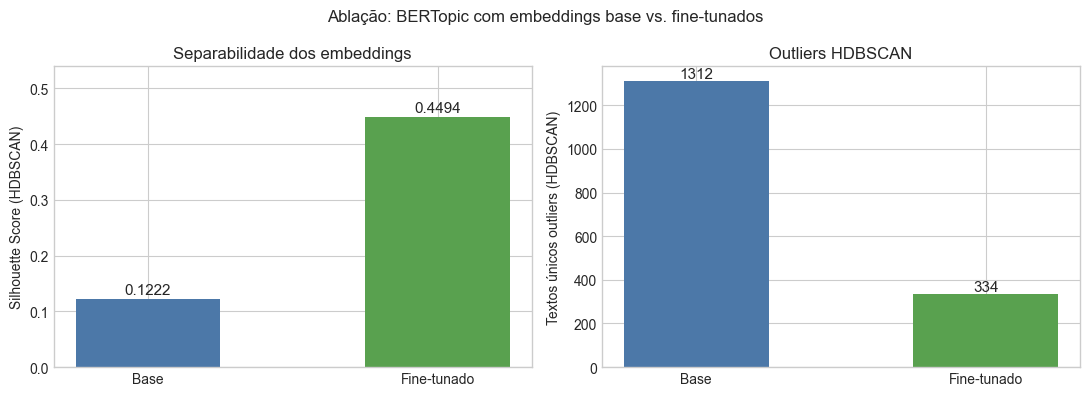

,Passagem,n_neighbors,min_topic_size,N Clusters,Outliers,Outlier %,Silhouette Score
0,Pass 1 — Modelo base,30,15,113,1312,18.9%,0.1222
1,Pass 2 — Fine-tunado,30,25,102,334,4.8%,0.4494


In [19]:
outlier_pct_pass1 = 100 * n_outliers_pass1 / len(card_topics_pass1)
outlier_pct_pass2 = 100 * n_outliers_pass2 / len(card_topics)
sil_gain = (sil_pass2 - sil_pass1) / sil_pass1 * 100

ablation_table = pd.DataFrame({
    "Passagem": ["Pass 1 — Modelo base", "Pass 2 — Fine-tunado"],
    "n_neighbors": [best_n_neighbors, best_n_neighbors_ft],
    "min_topic_size": [best_min_topic_size, best_min_topic_size_ft],
    "N Clusters": [n_clusters_pass1, n_clusters_pass2],
    "Outliers": [n_outliers_pass1, n_outliers_pass2],
    "Outlier %": [f"{outlier_pct_pass1:.1f}%", f"{outlier_pct_pass2:.1f}%"],
    "Silhouette Score": [round(sil_pass1, 4), round(sil_pass2, 4)],
})
print(f"Ganho de silhouette: +{sil_gain:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ["Base", "Fine-tunado"]
colors = ["#4C78A8", "#59A14F"]

axes[0].bar(labels, [sil_pass1, sil_pass2], color=colors, width=0.5)
for ax_bar, val in zip(axes[0].patches, [sil_pass1, sil_pass2]):
    axes[0].text(ax_bar.get_x() + ax_bar.get_width() / 2, val + 0.003, f"{val:.4f}", ha="center", va="bottom", fontsize=11)
axes[0].set_ylabel("Silhouette Score (HDBSCAN)")
axes[0].set_title("Separabilidade dos embeddings")
axes[0].set_ylim(0, max(sil_pass1, sil_pass2) * 1.2)

axes[1].bar(labels, [n_outliers_pass1, n_outliers_pass2], color=colors, width=0.5)
for ax_bar, val in zip(axes[1].patches, [n_outliers_pass1, n_outliers_pass2]):
    axes[1].text(ax_bar.get_x() + ax_bar.get_width() / 2, val + 0.5, str(val), ha="center", va="bottom", fontsize=11)
axes[1].set_ylabel("Textos únicos outliers (HDBSCAN)")
axes[1].set_title("Outliers HDBSCAN")

plt.suptitle("Ablação: BERTopic com embeddings base vs. fine-tunados", fontsize=12)
plt.tight_layout()
save_plot(fig, "ablation_silhouette.png")
plt.show()
ablation_table

## **7. Rotulagem Semântica dos Clusters via LLM**

O BERTopic (Passagem 2) agrupa textos em clusters de alta coesão semântica. A etapa de rotulagem mapeia cada cluster para um **grupo interpretável de infrações disciplinares**, fundamentado na Lei 12 do IFAB (*Fouls and Misconduct*) e adaptado ao vocabulário das súmulas CBF.

### Arquitetura do pipeline

- Para cada cluster, os **15 textos mais frequentes** são enviados ao Haiku como amostra representativa
- O LLM escolhe entre **19 grupos-semente** com descrições precisas (incluindo sinais positivos e fronteiras com grupos vizinhos)
- Outliers do HDBSCAN (cluster `-1`) são classificados individualmente em batches de 15
- Resultados são **cacheados em CSV** — re-execuções pulam itens já rotulados
- Se o LLM propõe um `NOVO:` grupo, o notebook exibe os exemplos para **revisão humana** antes de resolver o mapeamento

### Taxonomia de grupos (Lei 12 IFAB + prática CBF)

| Grupo | Base legal |
|---|---|
| Falta temerária em disputa de bola | Reckless challenge — cartão amarelo |
| Jogo brusco grave | Serious foul play / Violent conduct — cartão vermelho |
| Falta tática em ataque promissor | PAAOGG — cartão amarelo |
| Impedir clara oportunidade de gol | DOGSO — cartão vermelho |
| Toque de mão na bola | Handling — depende do contexto |
| Protesto ou reclamação contra a arbitragem | Dissent — cartão amarelo |
| Insubordinação da comissão técnica | Team official misconduct |
| Retardar reinício do jogo | Delaying restart — cartão amarelo |
| Não respeitar o local de saída em substituição | Delaying restart (substituição) |
| Agarrar ou puxar o adversário | Unsporting behaviour |
| Infração persistente às regras | Persistent offences — cartão amarelo |
| Comemoração irregular | Unsporting behaviour (comemoração) |
| Entrar, reentrar ou deixar o campo sem autorização | Entering field without permission |
| Gesto ou linguagem ofensiva | Offensive/abusive language — cartão vermelho |
| Confronto físico ou verbal | Violent conduct / unsporting behaviour |
| Simulação de falta | Deceiving the referee (feigning) |
| Não respeitar distância regulamentar em cobranças | Failing required distance |
| Dano a equipamento | Violent conduct (object) |
| Conduta antidesportiva | Unsporting behaviour (catch-all) |

### Score de representatividade

Após a rotulagem, um **score de representatividade** por texto é calculado como a similaridade cosseno entre o embedding do texto e o centroide ponderado (por `n_events`) do seu grupo. Score próximo de 1 = texto muito central no grupo; score baixo = texto na fronteira ou potencialmente mal classificado.


In [20]:
print_cluster_inspection(card_topic_model, card_text_counts, "bertopic_topic")

  ID   Eventos  Top terms
--------------------------------------------------------------------------------------------------------------

   9     2,147  calçar, calçar adversário temerária, calçar adversário, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário temerária
              > Por calçar seu adversário de maneira temerária na disputa de bola.
              > Por calçar seu adversário de maneira temerária, na disputa da bola
              > Por calçar seu adversário de forma temerária na disputa de bola.

  11     1,350  entrada temerária, entrada, dar entrada, dar entrada temerária, entrada temerária adversário, adversário dar entrada, temerária dar entrada, temerária adversário dar
              > Por dar uma entrada em seu adversário de maneira temerária na disputa de bola.
              > Por dar uma entrada temerária em seu adversário na disputa de bola.
              > Por dar uma entrada temerária em seu adversário n

In [21]:
from dotenv import load_dotenv
load_dotenv(PROJECT_ROOT / ".env")

import anthropic
import os
import re as _re
import time

LLM_MODEL = "claude-haiku-4-5-20251001"
LLM_N_EXAMPLES = 15
LLM_CLUSTER_CACHE_PATH = CARD_OUTPUT_DIR / "llm_cluster_labels.csv"
LLM_OUTLIER_CACHE_PATH = CARD_OUTPUT_DIR / "llm_outlier_labels.csv"
LLM_OUTLIER_BATCH_SIZE = 15

# Grupos derivados da validacao cluster a cluster (101 clusters + 334 outliers).
# Dois grupos sao lexicais: "Acao temeraria" (qualquer "temeraria/temerario") e
# "Jogo brusco grave" (qualquer "jogo brusco grave"). Os demais emergem dos dados.
SEED_GROUPS: dict[str, str] = {
    "Acao temeraria": (
        "Qualquer acao de jogo descrita como temeraria ou com temeridade: calcar, "
        "dar entrada, tranco, golpe, chute, pontape, rasteira, cotovelada ou atingir "
        "adversario de maneira/forma temeraria, com ou sem disputa de bola. "
        "Inclui uso temerario do braco para golpear o adversario durante disputa de bola.\n"
        "SINAL: 'temeraria', 'temerario', 'de maneira temeraria', 'de forma temeraria'.\n"
        "NAO usar: quando o texto diz 'jogo brusco grave' ou 'forca excessiva' sem "
        "'temeraria'; quando a acao e agarrar/segurar sem impacto fisico direto."
    ),
    "Jogo brusco grave": (
        "Qualquer texto com a expressao literal 'jogo brusco grave'. "
        "Tambem: acoes com uso de forca excessiva (especialmente fora da disputa de bola) "
        "sem usar a palavra 'temeraria': cotovelada no rosto, chute com travas na canela, "
        "empurrao violento pelas costas.\n"
        "SINAL: 'jogo brusco grave', 'forca excessiva', 'travas da chuteira'.\n"
        "NAO usar: quando a acao e descrita como temeraria (ver Acao temeraria); "
        "quando e apenas empurrao em disputa (ver Confronto fisico com adversario)."
    ),
    "Falta tatica em ataque promissor": (
        "Falta cometida por motivo tatico para impedir ou interromper ataque promissor "
        "(PAAOGG). Inclui calcar, segurar, puxar, derrubar, dar tranco impedindo ataque "
        "promissor, ou segurar adversario por motivo tatico para afasta-lo da bola.\n"
        "SINAL: 'falta tatica', 'ataque promissor', 'impedir um ataque promissor', "
        "'impedindo ataque promissor', 'motivo tatico', 'afasta-lo da bola'.\n"
        "NAO usar: quando menciona 'oportunidade clara de gol' (ver DOGSO); "
        "quando segurar e sem contexto de ataque promissor (ver Agarrar ou segurar adversario)."
    ),
    "Impedir clara oportunidade de gol (DOGSO)": (
        "Impedir uma oportunidade clara e manifesta de marcar gol (DOGSO). "
        "Acao que priva o adversario de uma finalizacao imediata e inequivoca.\n"
        "SINAL: 'oportunidade clara de gol', 'clara e manifesta oportunidade de gol', 'DOGSO'.\n"
        "NAO usar: quando menciona apenas 'ataque promissor' sem 'oportunidade clara' "
        "(ver Falta tatica em ataque promissor); quando e mao na bola sem DOGSO "
        "(ver Toque de mao na bola)."
    ),
    "Retardar reinicio do jogo": (
        "Atrasar deliberadamente o reinicio do jogo: chutar a bola para longe, segurar a "
        "bola com as maos, demorar excessivamente em cobranças (tiro de meta, tiro livre, "
        "arremesso lateral, escanteio, falta), ou retardar saida de campo durante substituicao.\n"
        "SINAL: 'retardar', 'demorar excessivamente', 'chutar a bola para longe', "
        "'retardar saida de campo', 'retardar a cobranca', 'retardar reinicio'.\n"
        "NAO usar: quando chutar a bola e explicitamente em forma de protesto "
        "(ver Protesto contra a arbitragem)."
    ),
    "Protesto contra a arbitragem": (
        "Reclamar, protestar ou desaprovar as decisoes ou marcacoes da equipe de arbitragem, "
        "de forma acintosa, ostensiva, com palavras e/ou gestos. Aplica-se a jogadores em "
        "campo ou ao sair. Inclui reclamacao persistente, aplaudir ironicamente, apontar dedo.\n"
        "SINAL: 'reclamar', 'protestar', 'desaprovar', 'contestar', 'decisoes da arbitragem', "
        "'marcacoes da arbitragem', 'acintosa', 'ostensiva'.\n"
        "NAO usar: quando protesto vem do banco de reservas ou area tecnica "
        "(ver Insubordinacao da comissao tecnica); quando foco e xingamento pessoal "
        "(ver Gesto ou linguagem ofensiva)."
    ),
    "Insubordinacao da comissao tecnica": (
        "Conduta irregular de membros da comissao tecnica ou jogadores no banco de reservas: "
        "sair da area tecnica para protestar, persistir em reclamar do banco, entrar em campo "
        "sem autorizacao vindo do banco. Inclui tecnicos, auxiliares, preparadores, medicos.\n"
        "SINAL: 'banco de reservas', 'banco de suplentes', 'area tecnica', 'sair da area tecnica', "
        "'comissao tecnica', funcao (tecnico, auxiliar, preparador, medico).\n"
        "NAO usar: quando e jogador em campo reclamando (ver Protesto contra a arbitragem)."
    ),
    "Agarrar ou segurar adversario": (
        "Agarrar, segurar ou puxar o adversario de forma acintosa ou grosseira, demonstrando "
        "desrespeito ao jogo, sem contexto explicito de falta tatica ou ataque promissor.\n"
        "SINAL: 'agarrar', 'segurar', 'puxar', 'pela camisa', 'desrespeito ao jogo', "
        "'de forma acintosa', 'impedindo de jogar'.\n"
        "NAO usar: quando ha mencao explicita a 'ataque promissor' (ver Falta tatica); "
        "quando e empurrao fisico com confronto (ver Confronto fisico com adversario)."
    ),
    "Confronto fisico com adversario": (
        "Empurroes, troca de empurroes, briga, desentendimento fisico ou verbal com adversario, "
        "geralmente com a bola fora de jogo ou a partida paralisada. Inclui inicio ou "
        "participacao em principio de tumulto entre jogadores.\n"
        "SINAL: 'empurrar', 'trocar empurroes', 'desentender', 'discutir com adversario', "
        "'confrontar adversario', 'bola fora de jogo', 'jogo paralisado'.\n"
        "NAO usar: quando e agarrar/segurar sem confronto (ver Agarrar ou segurar adversario); "
        "quando e protesto contra arbitro (ver Protesto contra a arbitragem)."
    ),
    "Conduta antidesportiva": (
        "Texto que usa 'conduta antidesportiva' ou 'atitude antidesportiva' como descricao "
        "da infracao sem detalhar a acao especifica, ou comportamentos que nao se encaixam "
        "nos demais grupos (desrespeito generico ao jogo).\n"
        "SINAL: 'conduta antidesportiva', 'atitude antidesportiva', 'desrespeito ao jogo' "
        "sem acao especifica associada.\n"
        "NAO usar: quando a acao especifica e descrita (usar o grupo correspondente)."
    ),
    "Comemoracao irregular": (
        "Comportamento irregular durante ou apos a comemoracao de gol: tirar a camisa, "
        "entrar no campo vindo do banco, subir na arquibancada ou escada, gestos provocativos "
        "para a torcida adversaria ou banco rival.\n"
        "SINAL: 'comemoracao', 'comemorar gol', 'tirar a camisa', 'invadir o campo para comemorar', "
        "'subir na arquibancada', 'gestos provocativos', 'frente ao banco adversario'.\n"
        "NAO usar: quando e invasao de campo sem contexto de comemoracao "
        "(ver Entrar ou sair do campo sem autorizacao)."
    ),
    "Simulacao": (
        "Tentar enganar o arbitro simulando ter sofrido falta, fingir lesao para obter "
        "vantagem ou simular penalidade.\n"
        "SINAL: 'simular', 'simulacao', 'tentar enganar o arbitro', 'simular uma falta', "
        "'simular tiro penal'."
    ),
    "Toque de mao na bola": (
        "Tocar a bola com a mao ou braco de forma intencional, bloquear a bola com o braco. "
        "O elemento central e o contato mao/braco com a BOLA, nao com o adversario.\n"
        "SINAL: 'mao na bola', 'tocar a bola com a mao', 'bloquear com o braco', "
        "'uso intencional das maos', 'colocar a mao na bola'.\n"
        "NAO usar: quando o braco atinge o adversario "
        "(ver Acao temeraria ou Jogo brusco grave)."
    ),
    "Entrar ou sair do campo sem autorizacao": (
        "Entrar no campo de jogo sem permissao do arbitro, retornar ao campo sem autorizacao "
        "apos atendimento, sair do campo sem permissao, ou fazer marcas nao autorizadas.\n"
        "SINAL: 'entrar no campo sem permissao', 'retornar sem autorizacao', 'reentrar', "
        "'marcas nao autorizadas', 'sem a permissao do arbitro'.\n"
        "NAO usar: quando e entrar para comemorar gol (ver Comemoracao irregular); "
        "quando e o banco invadindo (ver Insubordinacao da comissao tecnica)."
    ),
    "Infringir persistentemente as regras": (
        "Cometer infracoes repetidas ou variadas ao longo da partida, caracterizando "
        "persistencia no descumprimento das regras do jogo.\n"
        "SINAL: 'infringir persistentemente as regras', 'numero de diferentes infracoes', "
        "'persistencia em infracoes'.\n"
        "NAO usar: quando ha descricao especifica da infraco (usar o grupo correspondente)."
    ),
    "Nao respeitar distancia regulamentar": (
        "Nao manter a distancia minima obrigatoria na cobranca de tiro livre, tiro de canto "
        "ou outra situacao parada onde a regra exige afastamento minimo.\n"
        "SINAL: 'distancia regulamentar', 'distancia da barreira', 'distancia correta', "
        "'nao respeitar a distancia'.\n"
        "NAO usar: quando retardar a cobranca e o foco (ver Retardar reinicio do jogo)."
    ),
    "Gesto ou linguagem ofensiva": (
        "Xingamentos, insultos, palavroes ou gestos obscenos/ofensivos dirigidos ao arbitro, "
        "adversario ou outra pessoa, onde a ofensa pessoal e o motivo principal da punicao. "
        "Inclui palavras reportadas na sumula (filho da puta, vai tomar no cu) e gestos "
        "obscenos (dedo do meio, tocar orgao genital).\n"
        "SINAL: palavroes ou insultos citados diretamente, 'me senti ofendido', "
        "'palavras ofensivas', 'injuriosas', 'gesto obsceno'.\n"
        "NAO usar: quando o foco e reclamacao de decisoes sem ofensa pessoal explicita "
        "(ver Protesto contra a arbitragem)."
    ),
}


In [22]:
def _extract_json(text: str) -> dict:
    text = text.strip()
    match = _re.search(r'```(?:json)?\s*({.*?})\s*```', text, _re.DOTALL)
    if match:
        text = match.group(1)
    else:
        start, end = text.find('{'), text.rfind('}') + 1
        if start != -1 and end > start:
            text = text[start:end]
    return json.loads(text)


def _groups_list() -> str:
    return '\n'.join(f'- {name}' for name in SEED_GROUPS)


def _build_prompt(texts: list[str]) -> str:
    texts_block = '\n'.join(f'{i+1}. {t}' for i, t in enumerate(texts))
    groups = _groups_list()
    return (
        'Classifique cada justificativa de cartao de futebol em um dos grupos abaixo.\n\n'
        f"GRUPOS:\n{groups}\n\n"
        f"JUSTIFICATIVAS:\n{texts_block}\n\n"
        'Se nenhum grupo descrever bem a justificativa, use "NOVO: <nome>".\n\n'
        'Responda APENAS com JSON:\n'
        '{"classifications": [{"id": 1, "group": "nome"}, ...]}'
    )


def classify_clusters_llm(
    text_counts: pd.DataFrame,
    client,
    cache_path: Path,
    n_examples: int = LLM_N_EXAMPLES,
) -> dict[int, str]:
    cache: dict[int, str] = {}
    if cache_path.exists():
        cached_df = pd.read_csv(cache_path)
        cache = {int(r['cluster']): r['group'] for _, r in cached_df.iterrows()}

    clusters = sorted(c for c in text_counts['bertopic_topic'].unique() if c != -1)
    pending = [c for c in clusters if c not in cache]
    print(f'Clusters: {len(clusters)} | Cacheados: {len(cache)} | A rotular: {len(pending)}')

    for i, cluster_id in enumerate(pending):
        examples = (
            text_counts[text_counts['bertopic_topic'] == cluster_id]
            .nlargest(n_examples, 'n_events')['text_for_embedding']
            .tolist()
        )
        prompt = _build_prompt(examples)

        for attempt in range(3):
            try:
                response = client.messages.create(
                    model=LLM_MODEL,
                    max_tokens=1024,
                    messages=[{'role': 'user', 'content': prompt}],
                )
                parsed = _extract_json(response.content[0].text)
                votes = [item['group'] for item in parsed['classifications']]
                cache[cluster_id] = max(set(votes), key=votes.count)
                break
            except Exception as e:
                if attempt == 2:
                    print(f'  Falha cluster {cluster_id}: {e}')
                else:
                    time.sleep(2 ** attempt)

        if (i + 1) % 20 == 0 or i + 1 == len(pending):
            print(f'  {i+1}/{len(pending)} clusters rotulados')
        pd.DataFrame([{'cluster': k, 'group': v} for k, v in cache.items()]).to_csv(cache_path, index=False)

    return cache


def classify_outliers_llm(
    text_counts: pd.DataFrame,
    client,
    cache_path: Path,
    batch_size: int = LLM_OUTLIER_BATCH_SIZE,
) -> dict[str, str]:
    cache: dict[str, str] = {}
    if cache_path.exists():
        cached_df = pd.read_csv(cache_path)
        cache = dict(zip(cached_df['text'], cached_df['group']))

    outlier_texts = (
        text_counts[text_counts['bertopic_topic'] == -1]['text_for_embedding'].tolist()
    )
    pending = [t for t in outlier_texts if t not in cache]
    print(f'\nOutliers: {len(outlier_texts)} | Cacheados: {len(cache)} | A classificar: {len(pending)}')

    for batch_start in range(0, len(pending), batch_size):
        batch = pending[batch_start : batch_start + batch_size]
        prompt = _build_prompt(batch)

        for attempt in range(3):
            try:
                response = client.messages.create(
                    model=LLM_MODEL,
                    max_tokens=512,
                    messages=[{'role': 'user', 'content': prompt}],
                )
                parsed = _extract_json(response.content[0].text)
                for item in parsed['classifications']:
                    idx = item['id'] - 1
                    if 0 <= idx < len(batch):
                        cache[batch[idx]] = item['group']
                break
            except Exception as e:
                if attempt == 2:
                    print(f'  Falha outlier batch {batch_start}: {e}')
                else:
                    time.sleep(2 ** attempt)

        pd.DataFrame(list(cache.items()), columns=['text', 'group']).to_csv(cache_path, index=False)

    if pending:
        print(f'  {len(pending)} outliers classificados')
    return cache


def reconcile_new_groups(
    cluster_map: dict,
    outlier_map: dict,
    client,
    text_counts: pd.DataFrame | None = None,
) -> dict[str, str]:
    all_groups = set(cluster_map.values()) | set(outlier_map.values())
    new_names = sorted(g for g in all_groups if g.startswith('NOVO:'))
    if not new_names:
        print('Nenhum grupo novo proposto pelo LLM.')
        return {}

    sep = '=' * 65
    print(f'\n{sep}')
    print(f'  REVISAO NECESSARIA: {len(new_names)} grupo(s) novo(s) proposto(s)')
    print(f'  Avalie se SEED_GROUPS precisa de um novo grupo ou se o')
    print(f'  contexto esta pobre e o LLM deve usar um grupo existente.')
    print(sep)

    for g in new_names:
        cluster_hits = [k for k, v in cluster_map.items() if v == g]
        outlier_hits = [k for k, v in outlier_map.items() if v == g]
        print(f'\n  GRUPO SUGERIDO: {g}')
        print(f'  Clusters: {cluster_hits}  |  Outliers: {len(outlier_hits)}')
        if text_counts is not None:
            print('  Exemplos:')
            for c in cluster_hits[:2]:
                exs = (
                    text_counts[text_counts['bertopic_topic'] == c]
                    .nlargest(3, 'n_events')['text_for_embedding'].tolist()
                )
                for ex in exs:
                    print(f'    [{ex[:100]}]')
            for t in outlier_hits[:5]:
                print(f'    [{t[:100]}]')

    print(f'\n  -> Para adicionar: inclua o grupo em SEED_GROUPS e apague o cache.')
    print(f'  -> Para rejeitar: o LLM remapeia para o grupo existente mais proximo.')
    print(sep)

    if len(new_names) == 1:
        return {new_names[0]: new_names[0].replace('NOVO: ', '')}

    novo_list = '\n'.join(f'- {n}' for n in new_names)
    prompt = (
        'Grupos novos propostos para motivos de cartoes no futebol brasileiro.\n'
        'Mescle nomes similares em rotulos canonicos em portugues.\n\n'
        f'Grupos:\n{novo_list}\n\n'
        'Retorne APENAS JSON: {"mapping": {"nome_proposto": "nome_canonico"}}\n'
        'Sem prefixo NOVO: nos nomes canonicos.'
    )

    try:
        response = client.messages.create(
            model=LLM_MODEL, max_tokens=512,
            messages=[{'role': 'user', 'content': prompt}],
        )
        mapping = _extract_json(response.content[0].text)['mapping']
        print('\nMapeamento canonico aplicado:')
        for orig, canon in mapping.items():
            print(f'  {orig} -> {canon}')
        return mapping
    except Exception as e:
        print(f'Erro na reconciliacao: {e}')
        return {n: n.replace('NOVO: ', '') for n in new_names}


In [23]:
_client = anthropic.Anthropic(api_key=os.environ.get("ANTHROPIC_API_KEY"))

_cluster_map = classify_clusters_llm(card_text_counts, _client, LLM_CLUSTER_CACHE_PATH)
_outlier_map = classify_outliers_llm(card_text_counts, _client, LLM_OUTLIER_CACHE_PATH)
_canonical = reconcile_new_groups(_cluster_map, _outlier_map, _client, text_counts=card_text_counts)

def _resolve(group: str) -> str:
    return _canonical.get(group, group.replace("NOVO: ", "") if group.startswith("NOVO:") else group)

cluster_to_group = {c: _resolve(g) for c, g in _cluster_map.items()}
text_to_group = {t: _resolve(g) for t, g in _outlier_map.items()}

def _assign_group(row):
    if row["bertopic_topic"] != -1:
        return cluster_to_group.get(row["bertopic_topic"], "Outros")
    return text_to_group.get(row["text_for_embedding"], "Outros")

card_text_counts["card_reason_group"] = card_text_counts.apply(_assign_group, axis=1)
group_map = card_text_counts.set_index(CARD_TEXT_KEY_COLUMN)["card_reason_group"]
cards["card_reason_group"] = cards[CARD_TEXT_KEY_COLUMN].map(group_map).fillna("Outros")
CARD_GROUPS = sorted(cards["card_reason_group"].unique())

_group_counts = cards["card_reason_group"].value_counts()
print(f"\nGrupos finais ({len(CARD_GROUPS)}):")
for g in CARD_GROUPS:
    print(f"  {_group_counts.get(g, 0):6d} eventos  {g}")
print(f"\nOutros: {cards['card_reason_group'].eq('Outros').sum()}")


Clusters: 102 | Cacheados: 0 | A rotular: 102
  20/102 clusters rotulados
  40/102 clusters rotulados
  60/102 clusters rotulados
  80/102 clusters rotulados
  100/102 clusters rotulados
  102/102 clusters rotulados

Outliers: 334 | Cacheados: 0 | A classificar: 334
  334 outliers classificados

  REVISAO NECESSARIA: 1 grupo(s) novo(s) proposto(s)
  Avalie se SEED_GROUPS precisa de um novo grupo ou se o
  contexto esta pobre e o LLM deve usar um grupo existente.

  GRUPO SUGERIDO: NOVO: Invasão de campo e linguagem ofensiva
  Clusters: []  |  Outliers: 1
  Exemplos:
    [Após o término da partida o mesmo invadiu o campo de jogo e proferiu as seguintes palavras aos grito]

  -> Para adicionar: inclua o grupo em SEED_GROUPS e apague o cache.
  -> Para rejeitar: o LLM remapeia para o grupo existente mais proximo.

Grupos finais (25):
   11804 eventos  Acao temeraria
    2138 eventos  Agarrar ou segurar adversario
       3 eventos  Agarrar ou segurar adversário
     347 eventos  Ação temer

## **8. Resultados — Motivos de Cartão**

Cada cartão tem agora um grupo semântico em `card_reason_group`. As análises exploram a distribuição desses grupos ao longo do tempo, por tipo de cartão, por time e por árbitro.

### **8.1 Distribuição Geral**

In [24]:
card_group_summary = (
    cards.groupby("card_reason_group")
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
)
card_group_summary["pct_events"] = (card_group_summary["n_events"] / len(cards)).round(4)
card_group_summary

,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,pct_events
0,Acao temeraria,11804,11637,167,1931,0.4584
20,Protesto contra a arbitragem,3899,3801,98,992,0.1514
1,Agarrar ou segurar adversario,2138,2134,4,802,0.0830
10,Falta tatica em ataque promissor,2061,2053,8,412,0.0800
21,Retardar reinicio do jogo,1817,1808,9,623,0.0706
5,Conduta antidesportiva,748,746,2,271,0.0290
7,Confronto físico com adversário,612,601,11,303,0.0238
14,Infringir persistentemente as regras,383,383,0,121,0.0149
3,Ação temerária,347,16,331,250,0.0135
15,Insubordinacao da comissao tecnica,309,221,88,199,0.0120


In [25]:
card_group_by_year = pd.crosstab(cards["year"], cards["card_reason_group"], normalize="index").round(3)
card_group_by_year

card_reason_group,Acao temeraria,Agarrar ou segurar adversario,Agarrar ou segurar adversário,Ação temerária,Comemoracao irregular,Conduta antidesportiva,Confronto fisico com adversario,Confronto físico com adversário,Entrar ou sair do campo sem autorizacao,Entrar ou sair do campo sem autorização,...,Insubordinacao da comissao tecnica,Invasão de campo e linguagem ofensiva,Jogo brusco grave,Nao respeitar distancia regulamentar,Não respeitar distância regulamentar,Protesto contra a arbitragem,Retardar reinicio do jogo,Retardar reinício do jogo,Simulacao,Toque de mao na bola
year,,,,,,,,,,,,,,,,,,,,,
2020,0.497,0.079,0.0,0.017,0.006,0.016,0.004,0.026,0.010,0.0,...,0.009,0.0,0.013,0.001,0.001,0.139,0.065,0.0,0.004,0.013
2021,0.512,0.078,0.0,0.014,0.009,0.025,0.007,0.019,0.008,0.0,...,0.010,0.0,0.010,0.001,0.001,0.153,0.055,0.0,0.002,0.014
2022,0.460,0.085,0.0,0.013,0.013,0.037,0.013,0.025,0.010,0.0,...,0.009,0.0,0.011,0.001,0.000,0.160,0.065,0.0,0.001,0.011
2023,0.453,0.084,0.0,0.012,0.012,0.031,0.009,0.016,0.006,0.0,...,0.014,0.0,0.011,0.001,0.000,0.155,0.075,0.0,0.005,0.008
2024,0.427,0.079,0.0,0.012,0.011,0.032,0.013,0.024,0.008,0.0,...,0.017,0.0,0.011,0.000,0.000,0.157,0.087,0.0,0.006,0.005
2025,0.430,0.087,0.0,0.013,0.014,0.028,0.012,0.030,0.007,0.0,...,0.013,0.0,0.012,0.000,0.000,0.150,0.074,0.0,0.006,0.003
2026,0.409,0.099,0.0,0.014,0.015,0.039,0.007,0.030,0.006,0.0,...,0.009,0.0,0.009,0.000,0.001,0.138,0.071,0.0,0.012,0.001


In [26]:
card_group_by_type = pd.crosstab(cards["card_type"], cards["card_reason_group"])
card_group_by_type

card_reason_group,Acao temeraria,Agarrar ou segurar adversario,Agarrar ou segurar adversário,Ação temerária,Comemoracao irregular,Conduta antidesportiva,Confronto fisico com adversario,Confronto físico com adversário,Entrar ou sair do campo sem autorizacao,Entrar ou sair do campo sem autorização,...,Insubordinacao da comissao tecnica,Invasão de campo e linguagem ofensiva,Jogo brusco grave,Nao respeitar distancia regulamentar,Não respeitar distância regulamentar,Protesto contra a arbitragem,Retardar reinicio do jogo,Retardar reinício do jogo,Simulacao,Toque de mao na bola
card_type,,,,,,,,,,,,,,,,,,,,,
red,167,4,1,331,2,2,0,11,5,1,...,88,1,278,0,0,98,9,0,0,6
yellow,11637,2134,2,16,283,746,241,601,204,0,...,221,0,9,15,14,3801,1808,2,122,215


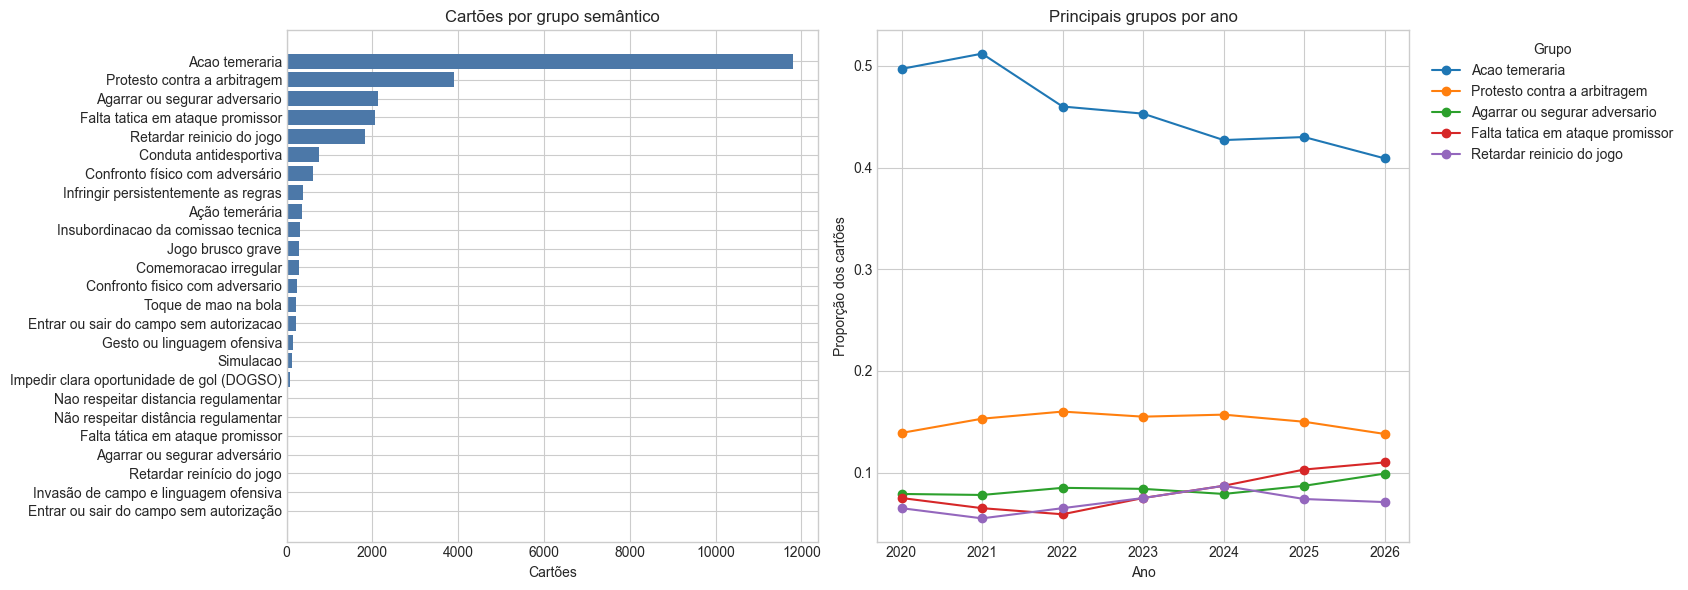

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
plot_card_summary = card_group_summary.sort_values("n_events", ascending=True)
axes[0].barh(plot_card_summary["card_reason_group"], plot_card_summary["n_events"], color="#4C78A8")
axes[0].set_title("Cartões por grupo semântico")
axes[0].set_xlabel("Cartões")
axes[0].set_ylabel("")

top_groups = card_group_summary.head(5)["card_reason_group"].tolist()
card_group_by_year[top_groups].plot(ax=axes[1], marker="o")
axes[1].set_title("Principais grupos por ano")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Proporção dos cartões")
axes[1].legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
save_plot(fig, "card_reason_groups_overview.png")
plt.show()

### **8.2 Por Time**

Para cada time, a tabela detalha a contagem de cada grupo semântico nos cartões recebidos. O perfil de motivos reflete o estilo de jogo: times com proporção elevada de "Ataque promissor / falta tática" tendem a ter linha defensiva mais agressiva; times com mais "Protesto contra arbitragem" apresentam comportamento mais reativo.

In [28]:
card_reason_by_team = (
    cards.groupby(["team", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
team_card_totals = cards.groupby("team").size().rename("total_cards")
card_reason_by_team = card_reason_by_team.merge(team_card_totals, on="team", how="left")
card_reason_by_team["pct_team_cards"] = (card_reason_by_team["n_events"] / card_reason_by_team["total_cards"]).round(4)
card_reason_by_team = card_reason_by_team.sort_values(["total_cards", "team", "n_events"], ascending=[False, True, False])

card_reason_top_by_team = (
    card_reason_by_team.sort_values(["team", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("team")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_team.head(30)

,team,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_team_cards
0,Red Bull Bragantino,Acao temeraria,493,488,5,161,999,0.4935
1,Fluminense,Acao temeraria,456,456,0,161,991,0.4601
2,Internacional,Acao temeraria,417,410,7,143,953,0.4376
3,São Paulo,Acao temeraria,406,399,7,146,950,0.4274
4,Palmeiras,Acao temeraria,419,411,8,134,937,0.4472
5,Corinthians,Acao temeraria,456,453,3,155,936,0.4872
6,Athletico Paranaense,Acao temeraria,401,394,7,143,883,0.4541
7,Atlético Mineiro,Acao temeraria,380,379,1,127,877,0.4333
8,Fortaleza Esporte Clube,Acao temeraria,396,393,3,132,851,0.4653
9,Flamengo,Acao temeraria,433,431,2,158,834,0.5192


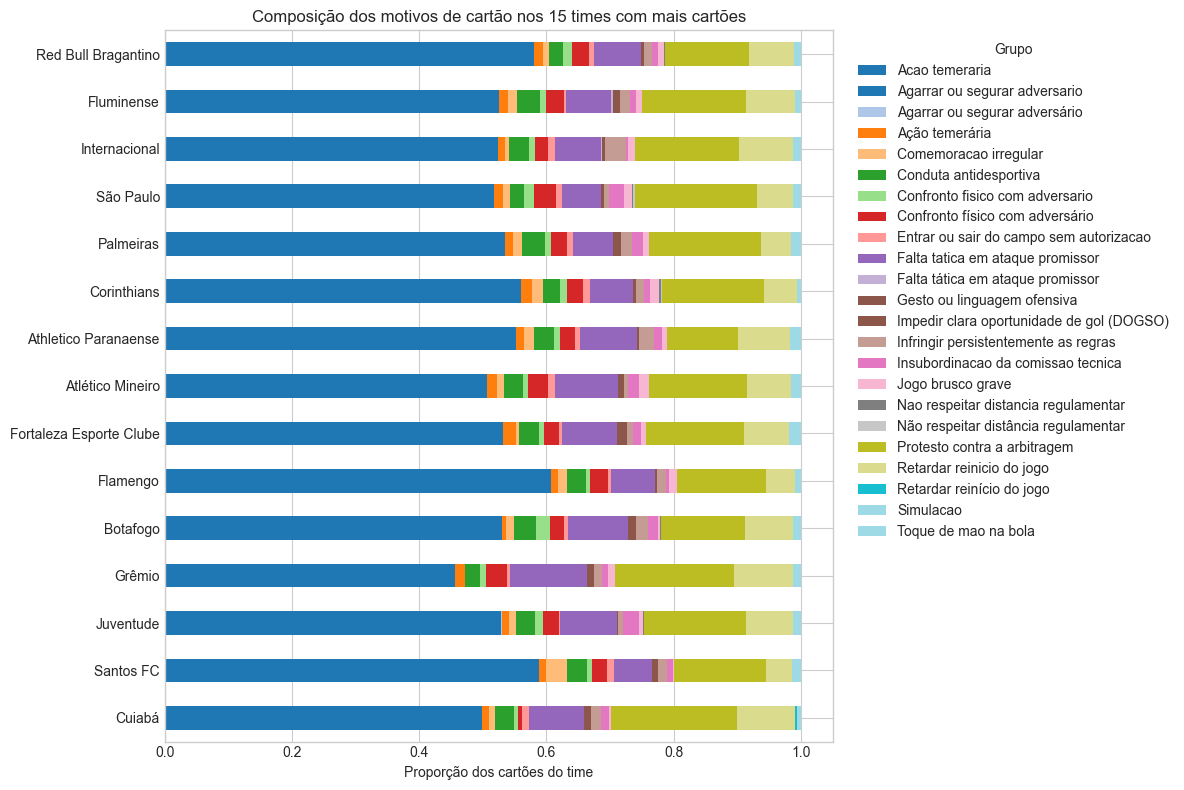

In [29]:
top_card_teams = cards["team"].value_counts().head(TOP_N_TEAMS).index
team_group_plot = pd.crosstab(
    cards.loc[cards["team"].isin(top_card_teams), "team"],
    cards.loc[cards["team"].isin(top_card_teams), "card_reason_group"],
    normalize="index",
).loc[top_card_teams]

fig, ax = plt.subplots(figsize=(12, 8))
team_group_plot.plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
ax.invert_yaxis()
ax.set_title(f"Composição dos motivos de cartão nos {TOP_N_TEAMS} times com mais cartões")
ax.set_xlabel("Proporção dos cartões do time")
ax.set_ylabel("")
ax.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_plot(fig, "card_reason_groups_by_team.png")
plt.show()

### **8.3 Por Árbitro**

A distribuição por árbitro mostra quais tipos de infrações são mais marcados nas partidas de cada árbitro. Árbitros com proporção elevada de "Protesto contra arbitragem" tendem a ser mais rigorosos com reclamações; árbitros com mais "Falta temerária" marcam faltas mais físicas.


In [30]:
card_reason_by_referee = (
    cards.groupby(["arbitro", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
referee_card_totals = cards.groupby("arbitro").size().rename("total_cards")
card_reason_by_referee = card_reason_by_referee.merge(referee_card_totals, on="arbitro", how="left")
card_reason_by_referee["pct_referee_cards"] = (card_reason_by_referee["n_events"] / card_reason_by_referee["total_cards"]).round(4)
card_reason_by_referee = card_reason_by_referee.sort_values(["total_cards", "arbitro", "n_events"], ascending=[False, True, False])

card_reason_top_by_referee = (
    card_reason_by_referee.sort_values(["arbitro", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("arbitro")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_referee.head(30)

,arbitro,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_referee_cards
0,Braulio da Silva Machado,Acao temeraria,513,507,6,97,1178,0.4355
1,Wilton Pereira Sampaio,Acao temeraria,537,532,5,155,1078,0.4981
2,Bruno Arleu de Araujo,Acao temeraria,562,548,14,170,1037,0.5419
3,Ramon Abatti Abel,Acao temeraria,442,438,4,167,993,0.4451
4,Flavio Rodrigues de Souza,Acao temeraria,426,419,7,129,921,0.4625
5,Raphael Claus,Acao temeraria,487,484,3,141,911,0.5346
6,Anderson Daronco,Acao temeraria,444,439,5,139,909,0.4884
7,Felipe Fernandes de Lima,Acao temeraria,346,346,0,142,847,0.4085
8,Savio Pereira Sampaio,Acao temeraria,356,355,1,133,829,0.4294
9,Wagner do Nascimento Magalhaes,Acao temeraria,395,393,2,134,799,0.4944


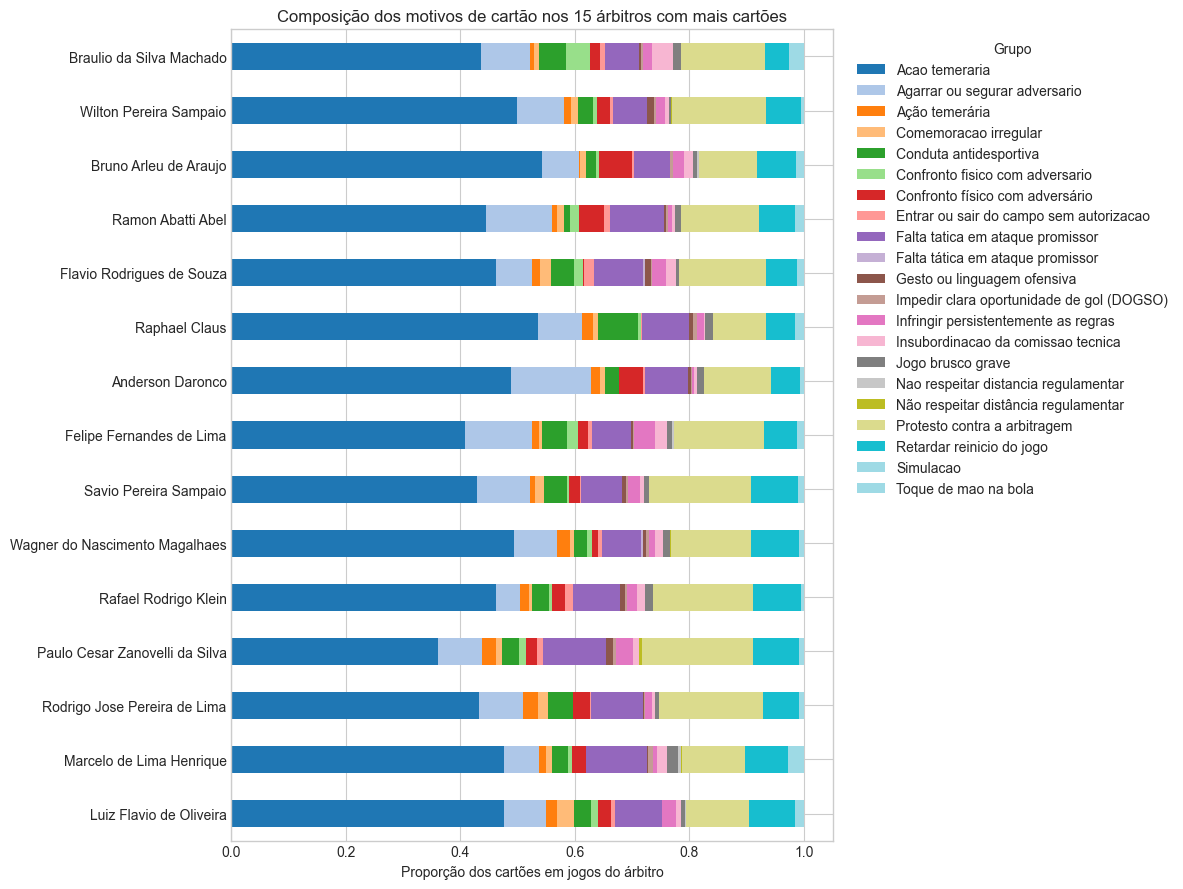

In [31]:
top_card_referees = cards["arbitro"].value_counts().head(TOP_N_REFEREES).index
referee_group_plot = pd.crosstab(
    cards.loc[cards["arbitro"].isin(top_card_referees), "arbitro"],
    cards.loc[cards["arbitro"].isin(top_card_referees), "card_reason_group"],
    normalize="index",
).loc[top_card_referees]

fig, ax = plt.subplots(figsize=(12, 9))
referee_group_plot.plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
ax.invert_yaxis()
ax.set_title(f"Composição dos motivos de cartão nos {TOP_N_REFEREES} árbitros com mais cartões")
ax.set_xlabel("Proporção dos cartões em jogos do árbitro")
ax.set_ylabel("")
ax.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_plot(fig, "card_reason_groups_by_referee.png")
plt.show()

### **8.4 Busca Semântica (Diagnóstico)**

Recupera os textos mais similares a uma consulta livre no espaço de embeddings fine-tunados. Útil para auditar se expressões semanticamente equivalentes ficaram no mesmo grupo e verificar a cobertura dos protótipos.

In [32]:
def embed_query(text: str) -> np.ndarray:
    return np.asarray(embedding_model.encode([ENCODE_PREFIX_QUERY + text], normalize_embeddings=True))

def semantic_search_cards(query: str, top_k: int = 10) -> pd.DataFrame:
    query_embedding = embed_query(query)
    similarities = cosine_similarity(query_embedding, card_embeddings).ravel()
    result = card_text_counts.copy()
    result["similarity"] = similarities
    return result.sort_values("similarity", ascending=False)[[
        "similarity", "n_events", "card_reason_group", "bertopic_topic", "text_for_embedding",
    ]].head(top_k)

semantic_search_cards("reclamação contra arbitragem", top_k=10)

,similarity,n_events,card_reason_group,bertopic_topic,text_for_embedding
4485,0.917319,1,Protesto contra a arbitragem,-1,Reclamar com arbitragem.
955,0.909394,4,Protesto contra a arbitragem,-1,Reclamação contra a arbitragem.
107,0.901274,30,Protesto contra a arbitragem,-1,Reclamar das decisões da arbitragem
1066,0.900900,3,Protesto contra a arbitragem,-1,Reclamar das marcações da arbitragem
2156,0.898229,2,Protesto contra a arbitragem,-1,Reclamação com a arbitragem com palavras
4499,0.897968,1,Protesto contra a arbitragem,-1,Reclamação contra a decisão da arbitragem
4592,0.894857,1,Protesto contra a arbitragem,-1,Reclamar contra decisões da arbitragem
48,0.893855,67,Protesto contra a arbitragem,-1,Reclamar contra as decisões da arbitragem
447,0.888547,7,Protesto contra a arbitragem,35,Por reclamação contra a arbitragem.
4002,0.886919,1,Protesto contra a arbitragem,35,Por reclamacao contra arbitragem.


## **9. Motivos de Acréscimos e Detecção de VAR**

Os motivos de acréscimos são tratados separadamente dos cartões. O único objetivo analítico é detectar se há menção ao VAR na justificativa de acréscimo registrada pelo árbitro.

A detecção é **léxica** — expressões regulares sobre o texto normalizado. Esta abordagem é suficiente porque a presença de VAR é um sinal fortemente textual: árbitros mencionam explicitamente "VAR", "AVAR", "revisão de vídeo" etc. quando o protocolo é ativado.

### **9.1 Exploração dos Textos de Atraso (BERTopic)**

BERTopic aplicado ao corpus de textos de atraso para mapear a diversidade temática. Esta etapa é exploratória — os clusters não são usados na detecção de VAR.

In [33]:
delay_text_counts = (
    delays[delays[DELAY_TEXT_COLUMN].ne("n/a")]
    .groupby("delay_reason_key")
    .agg(
        text_for_embedding=(DELAY_TEXT_COLUMN, "first"),
        n_games=(DELAY_TEXT_COLUMN, "size"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .reset_index()
    .sort_values("n_games", ascending=False)
    .reset_index(drop=True)
)
delay_text_counts.head(25)

,delay_reason_key,text_for_embedding,n_games,first_year,last_year
0,acrescimos devido as substituicoes e atendimento medico aos atletas,Acréscimos devido as substituições e atendimento médico aos atletas.,30,2020,2026
1,acrescimos devido substituicoes e transporte de atletas lesionados,Acréscimos devido substituições e transporte de atletas lesionados.,22,2020,2021
2,acrescimos devido a substituicoes atendimento medico e retirada de atletas supostamente lesionados do campo de jogo,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo.",14,2021,2023
3,acrescimos devido a substituicoes e atendimento de atletas supostamente lesionados,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .,13,2020,2025
4,acrescimos devido substituicoes atendimento medico aos atletas lesionados e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas.",13,2021,2025
5,acrescimos devido as substituicoes atendimento medico aos atletas e checagem do var,"Acréscimos devido as substituições, atendimento médico aos atletas e checagem do var.",12,2020,2022
6,nao houve atraso no inicio e reinicio de jogo acrescimos motivados por substituicoes e atendimento a jogadores supostamente lesionados,-nao houve atraso no inicio e reinicio de jogo.-acrescimos motivados por substituições e atendimento a jogadores supostamente lesionados.,11,2021,2025
7,acrescimos devido substituicoes atendimento medico aos atletas lesionados checagens do var e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados, checagens do var e paralisações diversas.",11,2023,2024
8,acrescimos devido substituicoes atendimento medico aos atletas lesionados e checagens do var,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e checagens do var.",11,2020,2022
9,acrescimos devido paralisacoes substituicoes e atendimento de atletas supostamente lesionados,"Acréscimos devido paralisações, substituições e atendimento de atletas supostamente lesionados.",10,2020,2024


In [34]:
delay_texts = delay_text_counts["text_for_embedding"].tolist()
delay_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in delay_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
delay_embeddings = np.asarray(delay_embeddings)
print(f"Embeddings de atrasos/acréscimos: {delay_embeddings.shape}")

Batches: 100%|██████████| 59/59 [01:02<00:00,  1.07s/it]

Embeddings de atrasos/acréscimos: (3764, 1024)


In [35]:
delay_topic_model = make_topic_model(DELAY_MIN_TOPIC_SIZE)
delay_topics, _ = delay_topic_model.fit_transform(delay_texts, embeddings=delay_embeddings)
delay_text_counts["bertopic_topic"] = delay_topics

delay_text_counts_for_summary = delay_text_counts.rename(columns={"n_games": "n_events"})
delay_topic_summary = build_topic_summary(delay_topic_model, delay_text_counts_for_summary, "bertopic_topic")
delay_topic_summary.head(20)

,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,0,879,0_substituições_acréscimos_atendimento_atletas,"[substituições, acréscimos, atendimento, atletas, lesionados, supostamente, supostamente lesionados, acréscimos substituições, substituições atendimento, atletas supostamente]","[Acréscimos para substituições e atendimento a atletas supostamente lesionados., Acréscimos devido as substituições e atendimento de atletas supostamente lesionados., Acréscimos devido à substituições e atendimento à...",879,1458,"substituições, acréscimos, atendimento, atletas, lesionados, supostamente, supostamente lesionados, acréscimos substituições"
1,1,426,1_homenagem_silêncio_respeitado_silêncio homenagem,"[homenagem, silêncio, respeitado, silêncio homenagem, homenagem póstuma, póstuma, respeitado silêncio, acréscimos, substituições, covid]","[Acréscimos devido a substituições, retirada de atletas supostamente lesionados do campo de jogo, reposição de bola e checagem do var. foi respeitado um minuto de silêncio em homenagem póstuma as vítimas do covid-19....",426,621,"homenagem, silêncio, respeitado, silêncio homenagem, homenagem póstuma, póstuma, respeitado silêncio, acréscimos"
2,-1,422,-1_atraso_ilustre_torcedor_fluminense,"[atraso, ilustre, torcedor, fluminense, entrada, informo, substituições, flamengo, acréscimos, lesionados]","[Informo que a equipe do sport clube do recife, retornou do intervalo de jogo com atraso de dois minutos, por este motivo o segundo tempo de jogo iniciou com atraso de um minuto. acréscimos motivados por atendimento ...",422,598,outliers
3,2,370,2_não_não houve_houve_não houve atraso,"[não, não houve, houve, não houve atraso, houve atraso, acréscimos, substituições, atrasos, atrasos acréscimos, houve atraso acréscimos]","[Não houve atraso. acréscimos por substituições e retirada de atletas supostamente lesionados., Não houve atraso. acréscimos devido a substituições, atendimento de atletas supostamente lesionados e reposição de bola....",370,542,"não, não houve, houve, não houve atraso, houve atraso, acréscimos, substituições, atrasos"
4,3,282,3_não houve_não_houve_homenagem,"[não houve, não, houve, homenagem, não houve atraso, silêncio, houve atraso, póstuma, homenagem póstuma, respeitado]","[Não houve atrasos. acréscimos devido as substituições, retirada de atletas supostamente lesionados e reposição de bola.informo que antes da partida foi respeitado um minuto de silêncio em homenagem póstuma as vitima...",282,451,"não houve, não, houve, homenagem, não houve atraso, silêncio, houve atraso, póstuma"
5,4,255,4_homenagem_silêncio_covid_respeitado,"[homenagem, silêncio, covid, respeitado, 19, covid 19, silêncio homenagem, acréscimos, 19 acréscimos, substituições]","[Foi respeitado 1 minuto de silêncio em homenagem as vitimas da covid 19.acréscimos devido a substituições e atendimento de atletas supostamente lesionados., Foi respeitado 1 minuto de silêncio de homenagem as vítima...",255,341,"homenagem, silêncio, covid, respeitado, 19, covid 19, silêncio homenagem, acréscimos"
6,6,188,6_primeiro_segundo_primeiro segundo_acréscimos primeiro,"[primeiro, segundo, primeiro segundo, acréscimos primeiro, segundo paralisações substituições, segundo paralisações, substituições, lesionados, atendimento, paralisações substituições]","[Acréscimos de 6 minutos no primeiro tempo, e 6 minutos no segundo tempo devido a paralisações, substituições, atendimento a atletas lesionados e checagem do var., Acréscimos de 6 minutos no primeiro tempo, e 7 minut...",188,277,"primeiro, segundo, primeiro segundo, acréscimos primeiro, segundo paralisações substituições, segundo paralisações, substituições, lesionados"
7,5,202,5_atraso_entrada_reinício_acréscimos,"[atraso, entrada, reinício, acréscimos, equipes, substituições, ambas, segundo, ambas equipes, atletas]",[Informo que ambas as equipes atrasaram em 5 minutos sua entrada em campo para a execução do protocolo de entrada e hino. em virtude d

In [36]:
delay_topic_examples = top_examples_by_topic(
    delay_text_counts.rename(columns={"n_games": "n_events"}),
    "bertopic_topic",
    top_n=5,
).rename(columns={"n_events": "n_games"})
delay_topic_examples.head(30)

,bertopic_topic,n_games,text_for_embedding
0,-1,2,"- acrescimos devido substituições , retirada de atletas do campo e revisões na ara.- concedido um minuto de silencio em homenagem postuma ao sr denis leitao de castro."
1,-1,2,"Acréscimos em função de atendimento a atletas supostamente lesionados, entrada da maca, substituições, checagem do var e comemorações de gols. informo que a equipe do bahia retornou para reinicio do jogo (segundo tem..."
2,-1,2,* acrescimos devido substituições e retirada de atletas do campo de jogo.* concedido um minuto de silencio em homenagem postuma as vitimas da covid19.
3,-1,2,Acrescimos devido substituições e retirada de atletas do campo de jogo. foi concedido um minuto de silencio em homenagem postumas a diego armando maradona e as vitimas da covid 19.
4,-1,2,Acréscimos devidos as substituições e atendimentos médico aos atletas lesionados.informo que a partida inicio com 2 minutos de atraso devido ao atraso de são paulo futebol clube de 3 minutos e da equipe saf botafogo ...
5,0,30,Acréscimos devido as substituições e atendimento médico aos atletas.
6,0,22,Acréscimos devido substituições e transporte de atletas lesionados.
7,0,14,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo."
8,0,13,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .
9,0,13,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas."


### **9.2 Detecção Léxica de VAR**

Os padrões cobrem siglas institucionais (`VAR`, `AVAR`, `VOR`, `ARA`), variações descritivas (`árbitro de vídeo`), termos de processo (`checagem`, `revisão`, `review`) e referências a infraestrutura (`monitor`, `cabine`). O sinal `monitor_cabine` é o mais ambíguo — "monitor" pode aparecer em contextos não-VAR.

In [37]:
VAR_SIGNAL_PATTERNS = {
    "var": r"\bvar\b",
    "avar": r"\bavar\b",
    "vor": r"\bvor\b|sala\s+vor",
    "ara": r"\bara\b",
    "arbitro_de_video": r"arbitro\s+de\s+video|arbitragem\s+de\s+video|video\s+arbitro",
    "checagem": r"checag(?:em|ens)|checando|checar",
    "revisao": r"revis(?:ao|oes|ar|ado|ada)|review",
    "monitor_cabine": r"\bmonitor\b|\bcabine\b",
}

def detect_var_signals(text: str) -> tuple[bool, str]:
    normalized = normalize_text(text)
    matches = [name for name, pattern in VAR_SIGNAL_PATTERNS.items() if re.search(pattern, normalized)]
    return bool(matches), ", ".join(matches)

var_detection = delays[DELAY_TEXT_COLUMN].apply(detect_var_signals)
delays["var_used"] = var_detection.map(lambda item: item[0])
delays["var_signal"] = var_detection.map(lambda item: item[1])

var_summary = pd.Series({
    "games_total": len(delays),
    "games_with_var_signal": int(delays["var_used"].sum()),
    "pct_with_var_signal": round(delays["var_used"].mean(), 4),
})
var_summary

games_total              5663.0000
games_with_var_signal    2031.0000
pct_with_var_signal         0.3586
dtype: float64

In [38]:
signal_counts = {}
for signal_name, pattern in VAR_SIGNAL_PATTERNS.items():
    signal_counts[signal_name] = delays[DELAY_TEXT_COLUMN].apply(
        lambda t, p=pattern: bool(re.search(p, normalize_text(str(t))))
    ).sum()

signal_dist = pd.Series(signal_counts, name='partidas').sort_values(ascending=False)
print('Frequência de cada sinal VAR:')
print(signal_dist.to_string())

only_monitor = (
    delays[delays['var_signal'].eq('monitor_cabine')]
    [[DELAY_TEXT_COLUMN, 'year']]
    .drop_duplicates(DELAY_TEXT_COLUMN)
    .sort_values('year')
    .reset_index(drop=True)
)
print(f'\nTextos ativados exclusivamente por monitor_cabine: {len(only_monitor)}')
print('Revisar manualmente para estimar precisão do detector neste sinal.')
only_monitor.head(15)

Frequência de cada sinal VAR:
var                 1745
checagem            1512
revisao              561
ara                  136
arbitro_de_video      79
vor                   48
monitor_cabine        36
avar                   2

Textos ativados exclusivamente por monitor_cabine: 1
Revisar manualmente para estimar precisão do detector neste sinal.


,delay_reason_clean,year
0,"Não houve atraso. os acréscimos foram dados por reposição da bola em jogo, gols, substituições atendimento ao goleiro mandante, tempo de cabine e retirada de atletas para atendimento.",2023


### **9.3 Evolução do VAR por Ano**

Proporção de partidas com sinal de VAR detectado por ano. Espera-se crescimento após a implementação do sistema no Campeonato Brasileiro a partir de 2019.

In [39]:
delay_var_by_year = (
    delays.groupby("year")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
    )
    .reset_index()
)
delay_var_by_year["pct_with_var_signal"] = (
    delay_var_by_year["games_with_var_signal"] / delay_var_by_year["games"]
).round(4)
delay_var_by_year

,year,games,games_with_var_signal,pct_with_var_signal
0,2020,880,211,0.2398
1,2021,882,375,0.4252
2,2022,882,340,0.3855
3,2023,882,347,0.3934
4,2024,882,325,0.3685
5,2025,882,326,0.3696
6,2026,373,107,0.2869


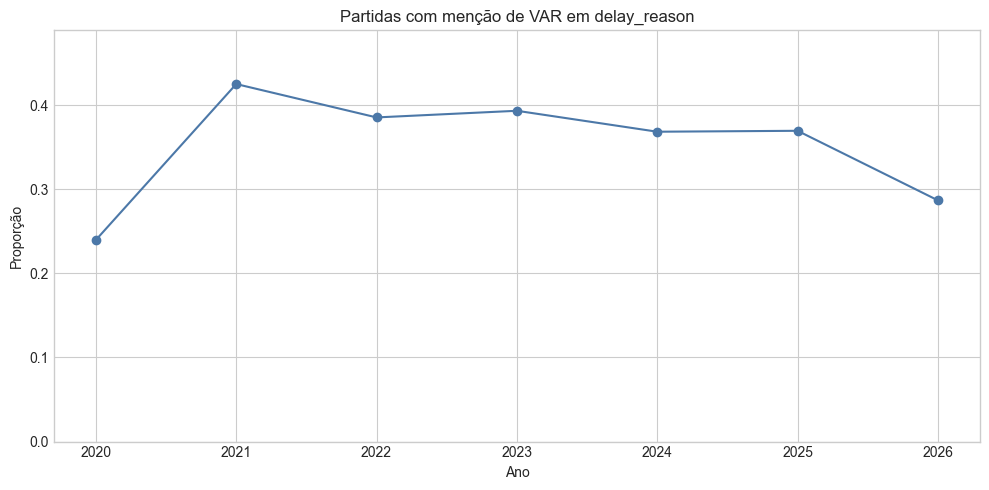

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(delay_var_by_year["year"], delay_var_by_year["pct_with_var_signal"], marker="o", color="#4C78A8")
ax.set_title("Partidas com menção de VAR em delay_reason")
ax.set_xlabel("Ano")
ax.set_ylabel("Proporção")
ax.set_ylim(0, max(0.05, delay_var_by_year["pct_with_var_signal"].max() * 1.15))
plt.tight_layout()
save_plot(fig, "var_mentions_by_year.png")
plt.show()

In [41]:
var_examples = (
    delays[delays["var_used"]]
    .sort_values(["year", "round", "game_number"])
    [["year", "round", "home_team", "away_team", "arbitro", "var_signal", DELAY_TEXT_COLUMN]]
    .head(25)
)
var_examples

,year,round,home_team,away_team,arbitro,var_signal,delay_reason_clean
10,2020,1,Santos FC,Red Bull Bragantino,Ricardo Marques Ribeiro,"var, checagem",Não houve atraso no inicio e reinicio do jogo. foi cumprido a diretriz técnica operacional da cbf de entrada das equipes 05 (cinco) minutos antes do jogo para equipe local (15:55) e 04 (quatro) minutos antes do jogo ...
19,2020,1,Sport Recife,Ceará,Edina Alves Batista,"var, checagem","Não houve atraso. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (20:55) e 4 (quatro) minutos antes do jogo para equipe visitante (20:56)..."
25,2020,1,Fortaleza Esporte Clube,Athletico Paranaense,Braulio da Silva Machado,"var, checagem","Não houve atraso no início e reinício de jogo. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (18:55) e 4 (quatro) minutos antes do jogo ..."
74,2020,2,Vasco da Gama,Sport Recife,Rodolpho Toski Marques,"var, revisao","Não houve atraso no início e reinício de jogo.foram acrescidos 2 minutos no primeiro tempo e 8 minutos no segundo tempo devido as substituições, reposição de bola em jogo, avaliação médica dos atletas supostamente le..."
83,2020,2,Atlético Mineiro,Corinthians,Wagner do Nascimento Magalhaes,var,"Não houve atraso no início e reinício da partida.acréscimos devido substituições,atendimento à atletas supostamente lesionados,reposição de bola em jogo e var.houve 01 minuto de silêncio em homenagem às vitimas do co..."
92,2020,2,Athletico Paranaense,Goiás,Diego Pombo Lopez,"var, checagem","Acréscimos no primeiro tempo devido a atendimento e retirada pela ambulância do atleta número 55 do athlético e também por checagens do var. acréscimos no segundo tempo devido a substituições, retirada de atletas sup..."
98,2020,2,Atlético,Flamengo,Luiz Flavio de Oliveira,"var, checagem","Não houve atrasos.acréscimos motivados por, atendimento médico, substituições, reposição de bola em jogo e checagem do var.informo que na relação nominal de atletas da equipe atletico cg, constava que o uniforme do g..."
120,2020,3,Fluminense,Internacional,Raphael Claus,"var, revisao","Não houve atraso no início e reinício da partida. houve acréscimos no primeiro e no segundo tempo de partida, devido as substituições, revisões do var, reposições de bola em jogo e atendimentos aos atletas supostamen..."
126,2020,3,Santos FC,Athletico Paranaense,Anderson Daronco,"var, checagem","Acréscimos de 4 minutos no primeiro tempo e 5 minutos no segundo tempo devido à paralisações, substituições, atendimento a atletas lesionados e checagem do var."
132,2020,3,Esporte Clube Bahia,Red Bull Bragantino,Felipe Fernandes de Lima,"var, checagem","Acréscimos devido as paralisações para retirada de atletas supostamente lesionados do campo de jogo, substituições e recuperação de tempo perdido por checagem do var.informo que foi respeitado um minuto de silêncio e..."


### **9.4 VAR por Time e Árbitro**

Para times: contagem sobre partidas em que o time aparece como mandante ou visitante — o mesmo jogo é contado para ambos. Para árbitros: contagem sobre as partidas apitadas. Em ambos os casos, `var_used` indica presença de sinal textual de VAR no campo de atraso, não validação externa do protocolo.

In [42]:
def most_common_non_empty(values: pd.Series) -> str:
    cleaned = values.astype(str).str.strip()
    cleaned = cleaned[cleaned.ne("")]
    if cleaned.empty:
        return ""
    return cleaned.value_counts().idxmax()

delay_home_games = delays.rename(columns={"home_team": "team", "away_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_away_games = delays.rename(columns={"away_team": "team", "home_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_team_games = pd.concat([delay_home_games, delay_away_games], ignore_index=True)

delay_var_by_team = (
    delay_team_games.groupby("team")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_team["pct_with_var_signal"] = (
    delay_var_by_team["games_with_var_signal"] / delay_var_by_team["games"]
).round(4)
delay_var_by_team = delay_var_by_team.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_team.head(30)

,team,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Red Bull Bragantino,456,174,"var, checagem",0.3816
1,Flamengo,443,189,"var, checagem",0.4266
2,Corinthians,442,194,"var, checagem",0.4389
3,Fluminense,442,173,"var, checagem",0.3914
4,Palmeiras,426,196,"var, checagem",0.4601
5,Internacional,417,177,"var, checagem",0.4245
6,Athletico Paranaense,398,170,"var, checagem",0.4271
7,São Paulo,396,207,"var, checagem",0.5227
8,Atlético Mineiro,396,146,"var, checagem",0.3687
9,Fortaleza Esporte Clube,368,158,"var, checagem",0.4293


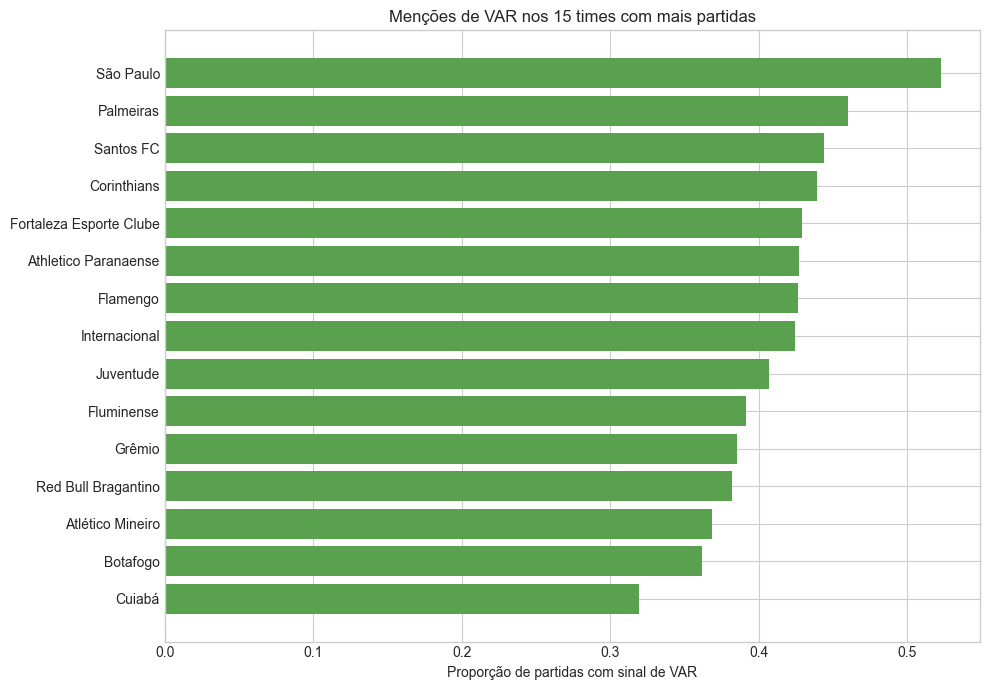

In [43]:
top_var_teams = delay_var_by_team.head(TOP_N_TEAMS).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_var_teams["team"], top_var_teams["pct_with_var_signal"], color="#59A14F")
ax.set_title(f"Menções de VAR nos {TOP_N_TEAMS} times com mais partidas")
ax.set_xlabel("Proporção de partidas com sinal de VAR")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "var_mentions_by_team.png")
plt.show()

In [44]:
delay_var_by_referee = (
    delays.groupby("arbitro")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_referee["pct_with_var_signal"] = (
    delay_var_by_referee["games_with_var_signal"] / delay_var_by_referee["games"]
).round(4)
delay_var_by_referee = delay_var_by_referee.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_referee.head(30)

,arbitro,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Anderson Daronco,255,83,"var, checagem",0.3255
1,Raphael Claus,243,80,"var, checagem",0.3292
2,Ramon Abatti Abel,233,102,"var, checagem",0.4378
3,Wilton Pereira Sampaio,223,103,"var, checagem",0.4619
4,Braulio da Silva Machado,222,131,"var, checagem",0.5901
5,Flavio Rodrigues de Souza,217,94,"var, checagem",0.4332
6,Bruno Arleu de Araujo,205,87,"var, checagem",0.4244
7,Savio Pereira Sampaio,190,80,"var, checagem",0.4211
8,Marcelo de Lima Henrique,175,67,"var, checagem",0.3829
9,Wagner do Nascimento Magalhaes,165,59,"var, checagem",0.3576


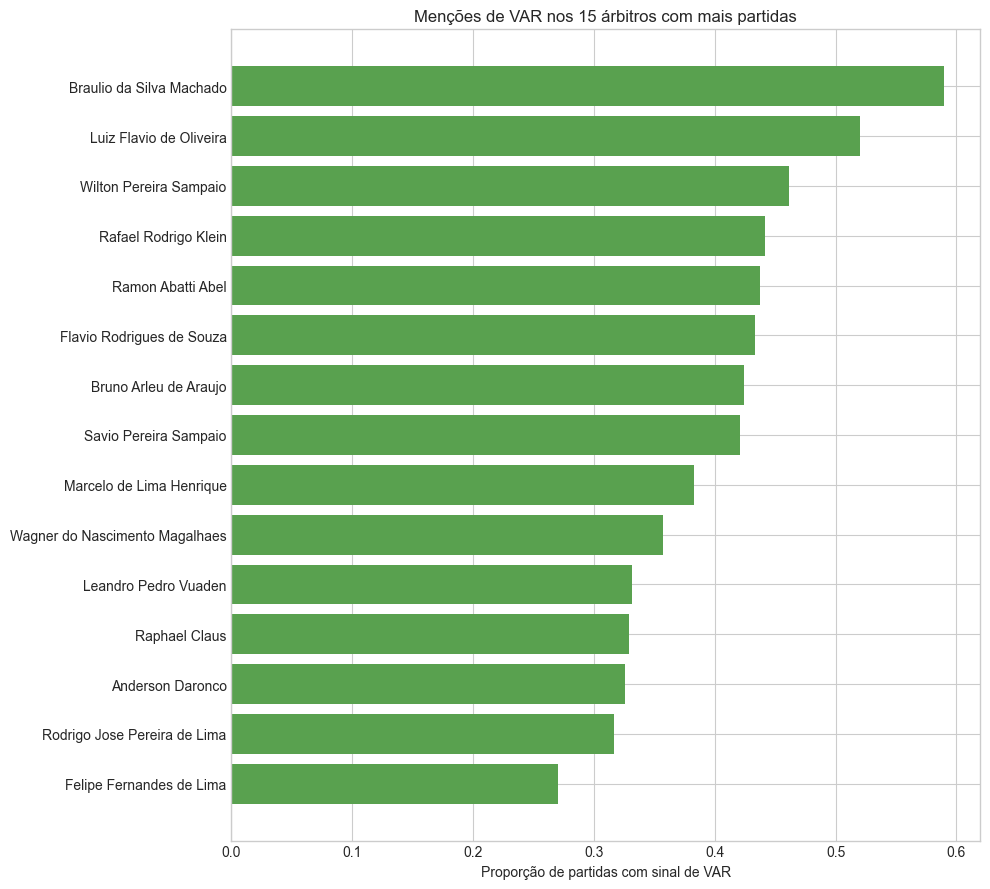

In [45]:
top_var_referees = delay_var_by_referee.head(TOP_N_REFEREES).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top_var_referees["arbitro"], top_var_referees["pct_with_var_signal"], color="#59A14F")
ax.set_title(f"Menções de VAR nos {TOP_N_REFEREES} árbitros com mais partidas")
ax.set_xlabel("Proporção de partidas com sinal de VAR")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "var_mentions_by_referee.png")
plt.show()

## **10. Salvamento dos Artefatos**

Arquivos gerados em `data/processed/semantic_reasons/card_reasons/`:

- `card_reasons_with_labels.csv` — dataset completo com grupo semântico por cartão
- `card_reason_group_summary.csv` — distribuição de eventos por grupo
- `card_reason_by_team.csv` / `card_reason_by_referee.csv` — tabelas analíticas
- `card_reason_outros_audit.csv` — textos não atribuídos (diagnóstico; vazio se cobertura total)

Visualizações em `viz/`.

In [46]:
outros_audit = (
    cards[cards["card_reason_group"].eq("Outros")]
    .groupby(CARD_TEXT_COLUMN)
    .size()
    .reset_index(name="n_events")
    .sort_values("n_events", ascending=False)
)

card_topic_summary_path = CARD_OUTPUT_DIR / "card_bertopic_topic_summary.csv"
card_topic_examples_path = CARD_OUTPUT_DIR / "card_bertopic_topic_examples.csv"
card_unique_topics_path = CARD_OUTPUT_DIR / "card_reason_unique_topics_labels.csv"
card_labeled_path = CARD_OUTPUT_DIR / "card_reasons_with_labels.csv"
card_group_summary_path = CARD_OUTPUT_DIR / "card_reason_group_summary.csv"
card_group_by_year_path = CARD_OUTPUT_DIR / "card_reason_group_by_year.csv"
card_group_by_type_path = CARD_OUTPUT_DIR / "card_reason_group_by_card_type.csv"
card_reason_by_team_path = CARD_OUTPUT_DIR / "card_reason_by_team.csv"
card_reason_top_by_team_path = CARD_OUTPUT_DIR / "card_reason_top_by_team.csv"
card_reason_by_referee_path = CARD_OUTPUT_DIR / "card_reason_by_referee.csv"
card_reason_top_by_referee_path = CARD_OUTPUT_DIR / "card_reason_top_by_referee.csv"
outros_audit_path = CARD_OUTPUT_DIR / "card_reason_outros_audit.csv"

delay_topic_summary_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_summary.csv"
delay_topic_examples_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_examples.csv"
delay_unique_topics_path = DELAY_OUTPUT_DIR / "delay_reason_unique_topics.csv"
delay_labeled_path = DELAY_OUTPUT_DIR / "delay_reasons_with_var.csv"
delay_var_by_year_path = DELAY_OUTPUT_DIR / "delay_var_by_year.csv"
delay_var_by_team_path = DELAY_OUTPUT_DIR / "delay_var_by_team.csv"
delay_var_by_referee_path = DELAY_OUTPUT_DIR / "delay_var_by_referee.csv"

card_topic_summary.to_csv(card_topic_summary_path, index=False)
card_topic_examples.to_csv(card_topic_examples_path, index=False)
card_text_counts.to_csv(card_unique_topics_path, index=False)
cards.to_csv(card_labeled_path, index=False)
card_group_summary.to_csv(card_group_summary_path, index=False)
card_group_by_year.to_csv(card_group_by_year_path)
card_group_by_type.to_csv(card_group_by_type_path)
card_reason_by_team.to_csv(card_reason_by_team_path, index=False)
card_reason_top_by_team.to_csv(card_reason_top_by_team_path, index=False)
card_reason_by_referee.to_csv(card_reason_by_referee_path, index=False)
card_reason_top_by_referee.to_csv(card_reason_top_by_referee_path, index=False)
outros_audit.to_csv(outros_audit_path, index=False)

delay_topic_summary.to_csv(delay_topic_summary_path, index=False)
delay_topic_examples.to_csv(delay_topic_examples_path, index=False)
delay_text_counts.to_csv(delay_unique_topics_path, index=False)
delays.to_csv(delay_labeled_path, index=False)
delay_var_by_year.to_csv(delay_var_by_year_path, index=False)
delay_var_by_team.to_csv(delay_var_by_team_path, index=False)
delay_var_by_referee.to_csv(delay_var_by_referee_path, index=False)

output_paths = [
    card_topic_summary_path,
    card_topic_examples_path,
    card_unique_topics_path,
    card_labeled_path,
    card_group_summary_path,
    card_group_by_year_path,
    card_group_by_type_path,
    card_reason_by_team_path,
    card_reason_top_by_team_path,
    card_reason_by_referee_path,
    card_reason_top_by_referee_path,
    outros_audit_path,
    delay_topic_summary_path,
    delay_topic_examples_path,
    delay_unique_topics_path,
    delay_labeled_path,
    delay_var_by_year_path,
    delay_var_by_team_path,
    delay_var_by_referee_path,
]

print("Arquivos salvos:")
for output_path in output_paths:
    print(f"  {output_path}")

Arquivos salvos:
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_examples.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_unique_topics_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reasons_with_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_year.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_card_type.csv
  /Users/gcarninatto/D